# 笔记 3：Model and Estimation（Section 4）的写作底稿

这份笔记把 **Section 4（Model and Estimation）** 用到的模型、推导、估计和检验集中在一处，供你梳理思路、自己写作。

- **每一节的结构：** 先给出完整推导（比论文详细得多，便于你自己把握），再用真实数据或模拟给出对应的数字，最后用"**写作要点**"说明哪些式子应进正文、哪些进附录、哪些可以不写。
- **口径：** v2 主规格，即 (d+1) PPS 候选集、方案 A（首次采纳）、24 小时会话。v2.1 把惯性组拆成**自供给**和**习惯**两组（§9），结果在 `results/tables/v2/v2s_*`。
- **代码：** 单元格已经运行过，输出就是结果。要重跑，在计算节点上执行 `jupyter nbconvert --execute`，大约需要 32 GB 内存。第 9 节的部分结果来自仍在运行的作业，重跑会自动读入新完成的部分。
- **符号：** 与草稿 `ec_adoption/sections/4_method.tex` 一致：$k$ 是一次选择（首次采纳），$\mathcal M_k$ 是市场，$\mathcal D_k$ 是抽样的候选集，$\pi_{kl}$ 是候选 $l$ 的入选概率，$x_{kl}$ 是特征，$\theta$ 是系数。

**目录**
0. 写作思路：这一节要讲清什么、按什么顺序讲、哪些式子进正文
1. 选择模型：从随机效用到条件 logit
2. 候选集抽样与修正（含三种抽样设计的对比）
3. 估计：似然、梯度、Hessian 与计算
4. 推断：按作者聚类的标准误与乘数 bootstrap
5. 样本外评价：留出集指标
6. 分解：Shapley 值
7. 通用质量的上界：枢纽固定效应
8. 方法能否区分机制：恢复检验
9. v2.1：样本、分组与加权的扩展
10. 重复选择与留存的模型（Section 5/6 和附录 E 用）
11. 式子清单：正文 / 附录 / 不写
12. 数字核对与草稿需要修改的地方
13. EC 审稿人可能的追问与回答

## 0. 写作思路

### 0.1 这一节的任务
Section 4 要让 EC 读者接受四件事：
1. **模型是标准的、可解释的。** 每次首次采纳是从市场中选一个父模型的离散选择，用条件 logit 描述；流行（优先连接）和"均匀连接"是它的特例。读者应该能一眼看出 $\theta$ 的含义。
2. **几十万个备选的计算问题被正确地解决了。** 对备选抽样，并用 $-\log\pi$ 修正，在 logit 下是精确的（Proposition）。按 degree 抽样不只是效率问题：均匀抽样会改变估计的权重。
3. **"流行 vs 适合"的结论来自一个不依赖顺序的分解。** 各组特征相关，所以用 Shapley 值分配似然增益；推断按作者聚类。
4. **结论不是测量缺失造成的，方法本身能区分机制。** 用枢纽固定效应给"通用质量"一个上界；在已知机制生成的选择上重跑分解，能把机制分开。

### 0.2 建议的段落顺序（与草稿一致，增加一处）

| # | 小节 | 一句话主张 | 核心式子 | 关键数字 | 本笔记 |
|---|---|---|---|---|---|
| 4.1 | 选择模型 | 首次采纳 = 条件 logit；均匀连接与优先连接是特例；$\theta$ 是描述性的权重 | (1) logit | — | §1 |
| 4.2 | 抽样 | 泊松 PPS 抽样，$\pi\propto d+1$；修正后的 logit 是精确的条件似然 | (2) $\pi$；Prop. 1 (3) | $S=300$；每个候选集约 8.5 个 $\pi=1$；27% 的被选父模型 $\pi=1$ | §2 |
| 4.3 | 估计与推断 | 全量数据，GPU 分桶；按作者聚类；乘数 bootstrap | （可选）加权似然 | 3,520 万行；6.2 万位训练作者；50 次 bootstrap | §3、§4 |
| 4.4 | 分解 | 似然增益的 Shapley 分解，样本内和留出集都报告 | (4) $G(\mathcal S)$、Shapley | $2^5=32$ 次拟合 | §5、§6 |
| 4.5 | 质量上界 | 500 个枢纽固定效应吸收全部不变属性；外部质量解释其中多少 | FE 模型、份额拆分 | FE 份额 42%；外部质量解释 7% | §7 |
| 4.6 | 恢复检验 | 已知机制生成的选择上重跑分解，能分开机制 | （文字） | SF 96.9% 流行；QF 94.0% 适合 | §8 |
| *新* | 样本与权重 | 主结果按选择加权、只用首次采纳；其他口径放 Section 5 的稳健性 | （文字或一行权重式） | 见 §9 | §9 |

### 0.3 主文放什么、附录放什么
- **正文的式子控制在 5–6 个：** logit、$\pi$ 的定义、修正后的 logit（Proposition）、$G(\mathcal S)$ 与 Shapley 值、FE 模型。§11 有完整的清单和理由。
- **附录 B：** Proposition 的证明、$c_k$ 的求解、分层与均匀设计的 $\log q$、作者历史的处理。
- **附录 C：** 梯度与 Hessian（凹性）、聚类标准误、设计效应、合成 PA 恢复、机制恢复、全量与 10% 样本对照。
- **附录 D/E：** 质量上界的噪声校正、留存模型、嵌套 logit 不可识别的证据。

### 0.4 EC 读者在这一节最可能追问的问题
（§13 有更完整的清单和建议的回答。）
- **IIA 的问题：** 抽样修正依赖 logit；如果偏好有异质性（混合 logit），修正还精确吗？
- **流行度是内生的：** degree 和不可观测的质量相关，$\theta_{\log d}$ 能解释为"跟风"吗？
- **选择集：** 开发者真的会考虑几十万个模型吗？考虑集（consideration set）的问题怎么处理？
- **Shapley 分解的单位：** "似然增益的份额"是什么意思？为什么不用"多少选择是流行驱动的"？

In [1]:
import os, sys, re, json, glob, pickle, warnings
os.environ.setdefault("ACMEC_DATA_ROOT", "/net/spaces/jevans/klab/caroyf/data/ACMEC")
sys.path.insert(0, "/home/caroyf/myproject/ACMEC/src")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")

DATA = "/net/spaces/jevans/klab/caroyf/data/ACMEC"
TAB = f"{DATA}/results/tables/v2"
CH = f"{DATA}/processed/choices/v2_pps"
REPO = "/home/caroyf/myproject/ACMEC"
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]; GRAY = "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6, "font.size": 9})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

def show(df, n=None):
    display(df if n is None else df.head(n))
def tab(name):
    return pd.read_csv(f"{TAB}/{name}.csv")
def pct(x, d=1):
    return f"{100 * x:.{d}f}%"
P5 = pickle.load(open(f"{CH}/v2_samples/P5/fit.pkl", "rb"))
print("main config:", P5["cfg"]); print("info:", P5["info"])

main config: {'sample': 'planA', 'groups': 'five', 'weight': 'choice', 'selfdeg': False, 'atype': None, 'drop_top': 0.0, 'fe': True}
info: {'n_train': 117509, 'n_hold': 15707, 'rows_train': 35189821, 'authors': 61635, 'hist_rows_share': 0.0, 'dropped': ['author_reuse', 'is_last']}


## 1. 选择模型：从随机效用到条件 logit

### 1.1 设定
首次采纳 $k$ 由作者 $a(k)$ 在时刻 $t_k$ 做出，从市场 $\mathcal M_k$ 中选一个父模型 $j_k$。市场 = 与子模型同模态、在 $t_k$ 之前创建、作者此前没用过的全部模型（Section 3）。作者对候选 $l$ 的效用为
$$U_{kl} = \theta^\top x_{kl} + \varepsilon_{kl}, \qquad \varepsilon_{kl} \overset{iid}{\sim} \text{Gumbel}(0,1).$$
$x_{kl}$ 随候选和时间变化；需求匹配和自供给 / 习惯特征还随作者变化。

### 1.2 推导：Gumbel 误差 ⇒ logit
令 $V_{kl} = \theta^\top x_{kl}$。Gumbel 分布的 CDF 是 $F(\varepsilon) = \exp(-e^{-\varepsilon})$，密度是 $f(\varepsilon) = e^{-\varepsilon}\exp(-e^{-\varepsilon})$。选 $j$ 的概率是 $j$ 的效用最大的概率：
$$
P(j) = \int f(\varepsilon_j) \prod_{l \ne j} F(\varepsilon_j + V_j - V_l)\, d\varepsilon_j
= \int e^{-\varepsilon} \exp\!\Big(-e^{-\varepsilon} \sum_{l} e^{-(V_j - V_l)}\Big) d\varepsilon .
$$
（$l=j$ 这一项正好是 $f$ 里的 $\exp(-e^{-\varepsilon})$。）令 $u = e^{-\varepsilon}$，$A = \sum_l e^{V_l - V_j}$，积分变为 $\int_0^\infty e^{-uA} du = 1/A$，所以
$$
P(j \mid \mathcal M_k) = \frac{\exp(\theta^\top x_{kj})}{\sum_{l\in\mathcal M_k}\exp(\theta^\top x_{kl})}. \tag{1}
$$

### 1.3 这个模型说了什么、没说什么
- **特例：**
  - $\theta = 0$：**均匀连接**，每个已存在的模型被选的概率相同，为 $1/|\mathcal M_k|$。
  - 只有 $\log d$ 和 $\mathbb 1[d>0]$：**优先连接**。$P \propto d^{\alpha}$（$d>0$），$\alpha = \theta_{\log d}$。$\alpha=1$ 是线性的 Barabási–Albert 模型。
  - 这正是 Overgoor, Benson & Ugander (2019) 的观点：物理学里的增长机制都是条件 logit 的特例，可以在一个似然下比较。
- **识别：** 只有**同一选择内跨候选**的差异能识别 $\theta$。只随作者变化、不随候选变化的变量（作者经验、是否机构）会在分子分母中相消，不能直接进入，只能通过与候选特征的交互进入。所以作者异质性在本文中通过两条路径处理：一是需求匹配特征本身（作者历史 × 候选），二是 v2.1 的按作者类型分开估计（§9）。
- **尺度：** Gumbel 的方差固定为 $\pi^2/6$，所以 $\theta$ 的单位是"相对于误差标准差"。不同样本之间系数的绝对大小不能直接比较，但**同一模型内**的相对大小和似然份额可以比较。
- **IIA：** 任意两个候选的概率比 $P(j)/P(l) = e^{V_j - V_l}$ 与其他候选无关。这一性质是 §2 抽样修正精确成立的关键，也是被批评最多的地方（§13）。
- **描述性的解释：** 本文把 $\theta$ 解释为"选择与哪些信号共变的最佳概括"，而不是因果效应。流行度与不可观测的质量相关，这一点由 §7 的上界处理。

### 1.4 系数的含义（主规格，无 FE）
下面的表给出主模型 P5 的系数、聚类标准误和 bootstrap 区间。几个读法：
- $\log d$：在已被使用的模型之间，$P \propto d^{\hat\alpha}$。$\hat\alpha$ 远小于 1，是**次线性**的优先连接。
- $\mathbb 1[d>0]$：从"没人用过"到"有人用过"，概率乘以 $e^{\hat\theta}$。这是一个巨大的**外延边际**。
- 二值特征：$e^{\hat\theta}$ 是其他特征不变时的概率比。

In [2]:
cf = tab("v2s_P5_clogit")
cf["odds_ratio"] = np.exp(cf.coef)
cols = [c for c in ["param", "group", "coef", "se_cl", "z", "lo", "hi", "odds_ratio", "coef_fe", "se_cl_fe"] if c in cf]
show(cf[cols].round(3))
a = cf.set_index("param").coef
print(f"sub-linear PA: P ∝ d^{a['log_deg']:.3f} among used models; first use multiplies odds by e^{a['has_deg']:.2f} = {np.exp(a['has_deg']):.0f}")

,param,group,coef,se_cl,z,lo,hi,odds_ratio,coef_fe,se_cl_fe
0,log_deg,pop,0.344,0.012,29.479,0.322,0.366,1.411,0.179,0.018
1,lrec30,pop,0.605,0.015,39.233,0.585,0.632,1.831,0.480,0.012
2,major_org,pop,0.650,0.031,20.897,0.585,0.702,1.916,1.614,0.042
3,has_deg,pop,4.637,0.081,57.088,4.415,4.763,103.196,3.834,0.081
4,legacy,pop,1.386,0.034,40.625,1.331,1.437,3.997,1.910,0.047
5,log_age,pop,-0.539,0.021,-25.890,-0.565,-0.502,0.583,-0.649,0.023
6,size_na,pop,-0.757,0.030,-24.853,-0.809,-0.707,0.469,-0.940,0.031
7,txt_na,pop,-0.439,0.087,-5.018,-0.576,-0.299,0.645,-0.437,0.103
8,bench_na,pop,-0.094,0.054,-1.759,-0.211,0.009,0.910,-0.176,0.111
9,lco2,pop,0.842,0.097,8.722,0.630,0.974,2.322,0.733,0.097


sub-linear PA: P ∝ d^0.344 among used models; first use multiplies odds by e^4.64 = 103


**写作要点：**
- **正文：** 只写 (1)，以及一句"$\theta=0$ 是均匀连接，只有 $\log d$ 时是优先连接"。Gumbel 推导是教科书内容，直接引用 McFadden (1974) 和 Train (2009)，不写。
- **把 $\theta$ 定位为描述性的权重：** 草稿已经这样写了，建议保留并指向 Discussion。这是 EC 审稿人会首先追问的地方。
- **次线性优先连接 + 巨大的外延边际：** 这个结果很直观，但它属于结果，建议放在 Section 5 第一段，不放在方法里。

## 2. 候选集抽样与修正

### 2.1 问题
训练集有 11.75 万次首次选择，每次的市场中位数约 34.5 万个模型。在完整市场上计算 (1) 需要约 $4\times10^{10}$ 个（选择，候选）对，在计算上不可行。所以从每个市场中抽一个候选集 $\mathcal D_k\subset\mathcal M_k$。

### 2.2 抽样方案（主规格：泊松 PPS）：$\pi$ 和 $c$ 从哪里来

**第一步：我们想要什么。** 越热门的模型越应该被抽中，因为它们是开发者真正比较的竞争者。具体地说，希望入选概率**与 degree + 1 成正比**：
$$\pi_{kl}\ \propto\ d_{kl}+1 .$$
（$d_{kl}$ 是 $l$ 在 $t_k$ 之前的 degree。$+1$ 是为了让 degree 为 0 的模型也有正的概率，因为修正要求每个模型的入选概率都大于 0。）

**第二步："成正比"只规定了比例，没有规定大小。** 它只说 degree 为 99 的模型被抽中的概率是 degree 为 0 的 100 倍，并没有说概率具体是多少。要把"成正比"写成等式，需要一个比例常数 $c_k$：
$$\pi_{kl} = c_k\,(d_{kl}+1).$$
**$c_k$ 就是这个比例常数，即"每单位 $(d+1)$ 的入选概率"。** degree 为 0 的模型入选概率是 $c_k$，degree 为 9 的是 $10c_k$。$c_k$ 越大，所有概率越大，候选集越大。

**第三步：概率不能超过 1。** 最热门的模型可能有 $c_k(d+1)>1$，这时截断为 1，表示它们必然入选：
$$\pi_{kl}=\min\{1,\ c_k (d_{kl} + 1)\}. \tag{2}$$

**第四步：选 $c_k$，使候选集大约有 $S=300$ 个候选。** 每个模型独立地决定是否入选（泊松抽样）。候选集的期望大小等于入选概率之和：令 $I_l=\mathbb 1[l\in\mathcal D_k]$，则 $|\mathcal D_k|=\sum_l I_l$；期望的线性性（不需要独立）给出
$$E|\mathcal D_k|=\sum_l E[I_l]=\sum_l\pi_{kl}.$$
例如三个模型的入选概率是 1、0.5、0.1，平均入选 1.6 个。令期望大小等于 300：
$$\sum_{l\in\mathcal M_k}\min\{1,\ c_k(d_{kl}+1)\}=300 .$$
式中除 $c_k$ 外都是已知的（每个模型的 degree），所以这是**一个只含未知数 $c_k$ 的方程，解出它就确定了概率的大小**。具体解法见 §2.5。

**为什么每次选择都有自己的 $c_k$：** 每次选择发生在不同时刻，市场的规模和 degree 分布都不同。要让每次都约有 300 个候选，就要为每次选择重新解一次。市场越大，$c_k$ 越小。

**最后：** 被选中的父模型 $j_k$ 总是加入 $\mathcal D_k$。如果它没被抽中，就把它补进去，其 $\pi$ 仍用它自己的值。

### 2.3 Proposition 1（抽样修正）及其证明
**命题：** 在 (1) 和抽样方案 (2) 下，
$$
P(j \mid \mathcal D_k) = \frac{\exp(\theta^\top x_{kj} - \log \pi_{kj})}{\sum_{l \in \mathcal D_k}\exp(\theta^\top x_{kl} - \log\pi_{kl})}. \tag{3}
$$
最大化 $\sum_k \log P(j_k\mid\mathcal D_k)$ 得到 $\theta$ 的一致估计。

**证明（McFadden 1978 的"正条件"论证）：**
1. **给定 $j$ 被选中，抽到某个集合 $\mathcal D \ni j$ 的概率。** 除 $j$ 以外的每个 $l$ 独立入选；$j$ 不论是否被抽中都会出现在 $\mathcal D$ 中，所以
$$ q(\mathcal D \mid j) = \prod_{l\in\mathcal D\setminus\{j\}}\pi_l \prod_{l\notin\mathcal D}(1-\pi_l). $$
2. **任意两个 $j, l\in\mathcal D$ 的比值。** 两式的乘积只在"$j$ 和 $l$ 各自那一项"上不同：$q(\mathcal D\mid j)$ 含 $\pi_l$ 而不含 $\pi_j$，$q(\mathcal D\mid l)$ 反之。所以
$$ \frac{q(\mathcal D\mid j)}{q(\mathcal D\mid l)} = \frac{\pi_l}{\pi_j}. $$
3. **贝叶斯公式。** 研究者观察到 $\mathcal D$ 和 $j$，则
$$
P(j\mid\mathcal D) = \frac{P(j)\,q(\mathcal D\mid j)}{\sum_{l\in\mathcal D}P(l)\,q(\mathcal D\mid l)}
= \frac{e^{V_j}\,q(\mathcal D\mid j)}{\sum_{l\in\mathcal D}e^{V_l}\,q(\mathcal D\mid l)}.
$$
用第 2 步把每个 $q(\mathcal D\mid l)$ 写成 $q(\mathcal D\mid j)\,\pi_j/\pi_l$：分母变为 $q(\mathcal D\mid j)\,\pi_j\sum_{l\in\mathcal D}e^{V_l}/\pi_l$，分子可以写成 $q(\mathcal D\mid j)\,\pi_j\,e^{V_j}/\pi_j$。公因子 $q(\mathcal D\mid j)\pi_j$ 相消，得到 $P(j\mid\mathcal D)=\frac{e^{V_j}/\pi_j}{\sum_{l\in\mathcal D}e^{V_l}/\pi_l}$，即 (3)。
4. **一致性。** (3) 是关于观测数据 $(j_k,\mathcal D_k)$ 的**正确设定的条件似然**。对所有 $j\in\mathcal D$ 都有 $q(\mathcal D\mid j)>0$，即正条件性质。所以标准的 M 估计论证给出一致性和渐近正态性（McFadden 1978；Train 2009 §3.7）。$\square$

**要点：** 证明在第 3 步用到了 $P(j) \propto e^{V_j}$，也就是 IIA。在混合 logit 下，$P(j)$ 不再是这种形式，修正只是近似（Guevara & Ben-Akiva 2013）。§9 按作者类型分开估计，部分回应了异质性的问题。

### 2.4 $-\log\pi$ 偏移的两个直观解释
- **Horvitz–Thompson：** $\sum_{l\in\mathcal D}e^{V_l}/\pi_l$ 是全市场分母 $\sum_{l\in\mathcal M}e^{V_l}$ 的无偏估计。抽中概率低的候选代表更多没被抽中的同类。
- **基准模型：** 在 $\theta=0$ 时，(3) 给每个抽中的候选权重 $1/\pi$。也就是说，"均匀连接"在抽样后仍然是"全市场每个模型等概率"。所以似然增益 $\ell(\hat\theta)-\ell(0)$ 有清楚的含义（§5、§6）。

### 2.5 求解 $c_k$：$\sum_l\pi_{kl}=S$ 是怎么解出来的

**第一步：回顾要解的方程（§2.2 第四步）。** 期望的候选集大小等于入选概率之和（期望的线性性），所以
$$E|\mathcal D_k| = \sum_{l\in\mathcal M_k}\Pr(l\in\mathcal D_k) = \sum_{l\in\mathcal M_k}\pi_{kl}.$$
令它等于目标大小 $S=300$，就得到一个只含一个未知数 $c_k$ 的方程：
$$\Sigma(c) \equiv \sum_{l\in\mathcal M_k}\min\{1,\ c\,(d_{kl}+1)\} = S.$$
（被选父模型若没被抽中会被补入，所以实际的平均大小略大于 $S$。方案 A 删去了作者历史，所以平均为 299.5。）

**第二步：按 degree 分组。** $\pi$ 只依赖于 degree，所以把市场按 degree 值分组：degree 为 $\delta$ 的模型有 $n_\delta$ 个（$\delta=0,1,2,\dots$，权重 $\delta+1$）。方程变为
$$\Sigma(c) = \sum_{\delta} n_\delta\,\min\{1,\ c(\delta+1)\} = S.$$

**第三步：$\Sigma(c)$ 的形状。** 每一项 $\min\{1, c(\delta+1)\}$ 都是 $c$ 的分段线性函数：
- $c < 1/(\delta+1)$ 时它等于 $c(\delta+1)$，随 $c$ 线性增长；
- $c \ge 1/(\delta+1)$ 时它**饱和**为 1，即这一组的模型必然入选。

degree 越大，饱和得越早。所以对任意 $c$，饱和的总是 **degree 最大的若干组**。$\Sigma(c)$ 连续、单调递增，从 0 增长到 $|\mathcal M_k|$，所以当 $|\mathcal M_k| > S$ 时方程有唯一解。

**第四步：给定"哪些组饱和"，方程是线性的。** 把正 degree 从大到小排成 $\delta_1>\delta_2>\dots$，假设恰好前 $m$ 组饱和：
$$\Sigma(c) = \underbrace{\sum_{i\le m}n_{\delta_i}}_{\text{饱和组：每个模型贡献 }1} + c\underbrace{\Big(n_0 + \sum_{i>m}n_{\delta_i}(\delta_i+1)\Big)}_{\text{未饱和组：贡献 }c(\delta+1)} = S$$
$$\Rightarrow\quad c_m = \frac{S - \sum_{i\le m}n_{\delta_i}}{n_0 + \sum_{i>m}n_{\delta_i}(\delta_i+1)}.$$
这就是 2.5 节那个式子的来历：**分子**是"还没被必然入选的模型占用的名额"，**分母**是未饱和模型的总权重。

**第五步：找出正确的 $m$。** $c_m$ 只有在与"前 $m$ 组饱和"的假设自洽时才是解：
- 第 $m$ 组确实饱和：$c_m(\delta_m+1)\ge 1$；
- 第 $m+1$ 组确实没有饱和：$c_m(\delta_{m+1}+1) < 1$；
- 零 degree 组没有饱和：$c_m \le 1$。

从 $m=0$ 开始依次尝试，第一个满足条件的 $m$ 就给出 $c_k$。由于 $\Sigma$ 单调，这样的 $m$ 唯一。如果 $|\mathcal M_k|\le S$，则全部模型入选，$c=\infty$。

**实现：** replay 按时间顺序处理选择，增量维护每个模态的 degree 直方图 $\{n_\delta\}$。每次只需按上面的方法遍历一遍不同的 degree 值（`replay.py::_pps_c`，同一时刻、同一模态的选择共用一个 $c$）。degree 为 0 的模型先抽二项分布 $\mathrm{Bin}(n_0, c)$ 的个数，再用拒绝抽样取出具体模型，这样不必逐个遍历几十万个零 degree 模型。

**下面用一个小例子演示：** 3 个模型 degree 为 99，10 个为 9，1,000 个为 0，目标 $S=50$。

In [3]:
def solve_c(hist, S):
    # hist: {degree: count}. Returns c with sum_delta n_delta * min(1, c (delta + 1)) = S (step 5 above).
    n0 = hist.get(0, 0)
    pos = sorted((d for d in hist if d > 0), reverse=True)
    if sum(hist.values()) <= S:
        return np.inf, []
    trace = []
    for m in range(len(pos) + 1):
        sat = sum(hist[d] for d in pos[:m])
        W = n0 + sum(hist[d] * (d + 1) for d in pos[m:])
        c = (S - sat) / W
        ok = (m == 0 or c * (pos[m - 1] + 1) >= 1) and (m == len(pos) or c * (pos[m] + 1) < 1) and c <= 1
        trace.append(dict(m=m, saturated_models=sat, unsaturated_weight=W, c=c, consistent=ok))
        if ok:
            return c, trace
    raise ValueError("no consistent m")

hist = {99: 3, 9: 10, 0: 1000}
c, trace = solve_c(hist, 50)
show(pd.DataFrame(trace).round(4))
pi = {d: min(1, c * (d + 1)) for d in hist}
print(f"c = {c:.5f}; pi: " + ", ".join(f"degree {d}: {p:.4f}" for d, p in pi.items()))
print(f"check: expected set size = {sum(hist[d] * pi[d] for d in hist):.4f} (target 50)")

,m,saturated_models,unsaturated_weight,c,consistent
0,0,0,1400,0.0357,False
1,1,3,1100,0.0427,True


c = 0.04273; pi: degree 99: 1.0000, degree 9: 0.4273, degree 0: 0.0427
check: expected set size = 50.0000 (target 50)


### 2.6 模拟演示：修正是否必要、PPS 是否更有效
下面在一个已知参数的合成市场上验证 Proposition 1：
- **市场：** 10,000 个模型，degree 服从重尾分布。效用 $V = 0.8\log(d+1) + 1.0\,x$，其中 $x$ 是随选择变化的"匹配"特征。
- **样本：** 每次重复生成 2,000 次选择（在完整市场上按 (1) 精确抽取），共重复 20 次。
- **四种估计：**
  1. 完整市场（基准）；
  2. PPS 抽样 + 修正（$E|\mathcal D|=100$）；
  3. 均匀抽样 + 修正（$|\mathcal D|\approx100$）；
  4. PPS 抽样但**不加修正**。

**预期：**
- 2、3 都无偏；
- 4 的 $\log(d+1)$ 系数应当偏低约 1，因为被省略的偏移 $-\log\pi = -\log c - \log(d+1)$ 恰好被这个系数吸收；匹配系数 $x$ 不受影响。

In [4]:
def fit_logit(sets, k, iters=50):
    # Newton on padded arrays: sets = list of (X [n, k], offset [n], chosen index)
    m = max(len(o) for _, o, _ in sets)
    X = np.zeros((len(sets), m, k)); O = np.full((len(sets), m), -np.inf); ch = np.zeros(len(sets), int)
    for i, (x, o, c) in enumerate(sets):
        X[i, :len(o)] = x; O[i, :len(o)] = o; ch[i] = c
    rows = np.arange(len(sets))
    def evalf(th):
        v = X @ th + O
        mx = v.max(1, keepdims=True)
        e = np.exp(v - mx); den = e.sum(1, keepdims=True)
        ll = float((v[rows, ch] - mx[:, 0] - np.log(den[:, 0])).sum())
        return ll, e / den
    th = np.zeros(k)
    ll, p = evalf(th)
    for _ in range(iters):
        xb = (p[..., None] * X).sum(1)
        g = (X[rows, ch] - xb).sum(0)
        dx = X - xb[:, None, :]
        H = -np.einsum("cs,csi,csj->ij", p, dx, dx)
        step = -np.linalg.solve(H, g)       # Newton ascent direction (H negative definite)
        t = 1.0
        while True:                          # backtracking: the log-likelihood is concave
            ll_new, p_new = evalf(th + t * step)
            if ll_new >= ll - 1e-10 or t < 1e-6:
                break
            t /= 2
        th, ll, p = th + t * step, ll_new, p_new
        if np.abs(t * step).max() < 1e-8:
            break
    return th, np.sqrt(np.diag(np.linalg.inv(-H)))

rng = np.random.default_rng(0)
N, K, R, S = 10_000, 2_000, 20, 100
d = np.minimum(np.floor(rng.pareto(1.1, N) * 1.5), 5000).astype(int)
ld = np.log1p(d); theta = np.array([0.8, 1.0])
pi_unc = np.minimum(1, (d + 1) * S / (d + 1).sum())
for _ in range(30):   # solve c with saturation (eq. 2)
    c = (S - (pi_unc >= 1).sum()) / ((d + 1) * (pi_unc < 1)).sum()
    pi_unc = np.minimum(1, c * (d + 1))
res = {k: [] for k in ["full market", "PPS + correction", "uniform + correction", "PPS, no correction"]}
for r in range(R):
    sets = {k: [] for k in res}
    for _ in range(K):
        x = rng.normal(size=N)
        V = theta[0] * ld + theta[1] * x
        j = np.argmax(V + rng.gumbel(size=N))
        Xf = np.column_stack([ld, x])
        if r < 3:   # the full-market fit is slow; 3 replicates suffice for the benchmark
            sets["full market"].append((Xf, np.zeros(N), j))
        for name, pi in (("PPS", pi_unc), ("uniform", np.full(N, S / N))):
            take = rng.random(N) < pi; take[j] = True
            idx = np.flatnonzero(take); cpos = int(np.flatnonzero(idx == j)[0])
            if name == "PPS":
                sets["PPS + correction"].append((Xf[idx], -np.log(pi[idx]), cpos))
                sets["PPS, no correction"].append((Xf[idx], np.zeros(len(idx)), cpos))
            else:
                sets["uniform + correction"].append((Xf[idx], -np.log(pi[idx]), cpos))
    for k_, s_ in sets.items():
        if s_:
            res[k_].append(fit_logit(s_, 2)[0])
sim = pd.DataFrame({k: dict(mean_log_deg=np.mean([t[0] for t in v]), sd_log_deg=np.std([t[0] for t in v], ddof=1),
                            mean_x=np.mean([t[1] for t in v]), sd_x=np.std([t[1] for t in v], ddof=1), reps=len(v))
                    for k, v in res.items()}).T
print(f"truth: log(d+1) {theta[0]}, x {theta[1]}; pi = 1 for {(pi_unc >= 1).sum()} models")
show(sim.round(3))

truth: log(d+1) 0.8, x 1.0; pi = 1 for 9 models


,mean_log_deg,sd_log_deg,mean_x,sd_x,reps
full market,0.795,0.012,0.997,0.013,3.0
PPS + correction,0.800,0.011,1.003,0.021,20.0
uniform + correction,0.800,0.011,1.005,0.029,20.0
"PPS, no correction",-0.135,0.013,1.001,0.021,20.0


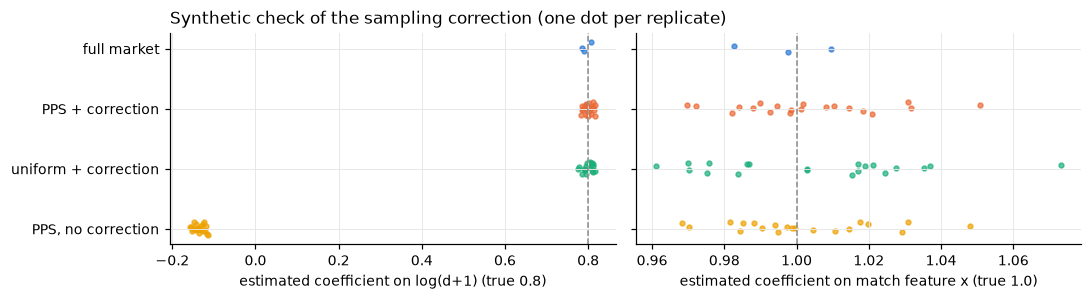

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(10, 2.8), sharey=True)
names = list(res)
for a_, (col, lab_, tv) in zip(axs, [(0, "log(d+1)", theta[0]), (1, "match feature x", theta[1])]):
    for i, k_ in enumerate(names):
        v = np.array(res[k_])[:, col]
        a_.scatter(v, np.full(len(v), i) + rng.uniform(-0.12, 0.12, len(v)), s=10, color=C[i], alpha=0.7)
    a_.axvline(tv, color=GRAY, lw=1, ls="--")
    a_.set_xlabel(f"estimated coefficient on {lab_} (true {tv})")
axs[0].set_yticks(range(len(names))); axs[0].set_yticklabels(names); axs[0].invert_yaxis()
axs[0].set_title("Synthetic check of the sampling correction (one dot per replicate)", loc="left")
plt.tight_layout(); plt.show()

**怎么读：**
- 修正后的两种抽样都围绕真值，与完整市场的估计一致。
- 不加修正时，$\log(d+1)$ 的系数系统性地偏低，偏差接近 1，就是被省略的偏移；匹配系数不受影响。
- **效率：** 在这个小市场里，两种设计对 $\log(d+1)$ 系数的精度相当；但均匀抽样下匹配系数 $x$ 的标准差约大 40%。原因是 PPS 把被选中概率高的候选（热门模型）放进候选集，被选者与"真正的竞争者"之间的对比更多，每次选择提供的信息更多。

在真实数据中，差别比这里大得多：市场是 34 万而不是 1 万，均匀抽出的候选集几乎从不包含热门模型。§2.8 显示，均匀设计的聚类标准误中位数是 PPS 的 2.2 倍，而且估计的权重本身也发生了变化。

### 2.7 真实候选集的描述与 HT 检验
下面读取主规格候选集中的 `log_q`（即 $\log\pi$），描述三件事：
- 每个候选集里 $\pi=1$ 的候选有几个，被选父模型有多大比例落在 $\pi=1$ 的层；
- 被选父模型的 $\pi$ 的分布；
- **HT 检验：** $\hat N_k = 1 + \sum_{l\in\mathcal D_k\setminus\{j_k\}} 1/\pi_{kl}$ 应当是市场规模 $|\mathcal M_k|$ 的无偏估计。这里用"同模态、更早创建"的模型数作为 $|\mathcal M_k|$ 的近似；方案 A 还会去掉作者用过的父模型，这部分很小。

In [6]:
from hfpa.v2data import load_choices
ch = load_choices("v2_pps")
ids = set(ch.index[ch.pair_first.to_numpy()])
parts = []
for f in sorted(glob.glob(f"{CH}/feats/*.parquet")):
    if f.endswith(".notext.parquet"):
        continue
    x = pd.read_parquet(f, columns=["choice_id", "chosen", "log_q", "author_reuse", "fe"])
    parts.append(x[x.choice_id.isin(ids) & (x.author_reuse == 0)])
R_ = pd.concat(parts, ignore_index=True)
R_["inv"] = np.exp(-R_.log_q.astype(np.float64))
g = R_.groupby("choice_id")
cs = pd.DataFrame({"size": g.size(), "certain": (R_.log_q == 0).groupby(R_.choice_id).sum(),
                   "ht": 1 + R_[R_.chosen == 0].groupby("choice_id").inv.sum()})
chosen_lq = R_[R_.chosen == 1].set_index("choice_id").log_q
cs["chosen_pi1"] = (chosen_lq.reindex(cs.index) == 0)
cs["holdout"] = ch.holdout.reindex(cs.index).to_numpy()
tr = cs[~cs.holdout]
print(f"choices {len(cs):,} (train {len(tr):,}); rows {len(R_):,} (train {int(tr['size'].sum()):,})")
print(f"set size: mean {cs['size'].mean():.1f}, median {cs['size'].median():.0f}; pi = 1 per set: mean "
      f"{cs.certain.mean():.2f} (all), {tr.certain.mean():.2f} (train)")
print(f"chosen parent has pi = 1: {pct(cs.chosen_pi1.mean())} (all), {pct(tr.chosen_pi1.mean())} (train)")
hub = R_.fe.to_numpy() > 0
print(f"rows of the 500 FE hubs: {hub.sum():,}; of these with pi < 1 (offset != 0): {pct((R_.log_q.to_numpy()[hub] < 0).mean())}")
# true market size: same modality, born before t
nodes = pd.read_parquet(f"{DATA}/processed/nodes/nodes.parquet", columns=["birth", "modality_code"])
true_n = np.zeros(len(cs))
cc = ch.reindex(cs.index)
for m, grp in cc.groupby("modality"):
    b = np.sort(nodes.birth.to_numpy()[nodes.modality_code.to_numpy() == m])
    true_n[cc.index.get_indexer(grp.index)] = np.searchsorted(b, grp.t.to_numpy(), "left")
cs["true_n"] = true_n
ratio = cs.ht / cs.true_n
print(f"HT market size / true market size: mean {ratio.mean():.3f}, median {ratio.median():.3f}, "
      f"5-95% [{ratio.quantile(.05):.3f}, {ratio.quantile(.95):.3f}]")

choices 133,390 (train 117,642); rows 39,946,463 (train 35,229,760)
set size: mean 299.5, median 299; pi = 1 per set: mean 8.55 (all), 8.39 (train)
chosen parent has pi = 1: 27.1% (all), 27.8% (train)
rows of the 500 FE hubs: 4,293,149; of these with pi < 1 (offset != 0): 73.6%


HT market size / true market size: mean 1.000, median 0.999, 5-95% [0.898, 1.104]


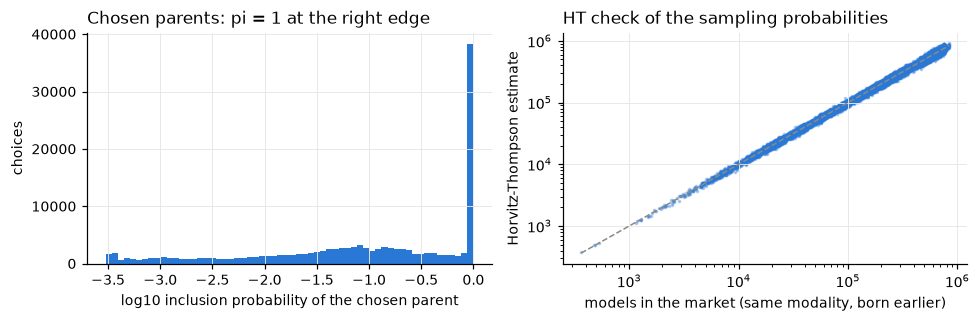

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3))
pi_ch = np.exp(chosen_lq.to_numpy())
axs[0].hist(np.log10(pi_ch), bins=60, color=C[0])
axs[0].set_xlabel("log10 inclusion probability of the chosen parent"); axs[0].set_ylabel("choices")
axs[0].set_title("Chosen parents: pi = 1 at the right edge", loc="left")
s_ = cs.sample(min(20000, len(cs)), random_state=0)
axs[1].scatter(s_.true_n, s_.ht, s=2, alpha=0.3, color=C[0])
lim = [s_.true_n.min(), s_.true_n.max()]
axs[1].plot(lim, lim, color=GRAY, lw=1, ls="--")
axs[1].set_xscale("log"); axs[1].set_yscale("log")
axs[1].set_xlabel("models in the market (same modality, born earlier)"); axs[1].set_ylabel("Horvitz-Thompson estimate")
axs[1].set_title("HT check of the sampling probabilities", loc="left")
plt.tight_layout(); plt.show()

### 2.8 三种抽样设计的对比（回答"为什么第 9 节只有一种"）
replay 同时生成了三套候选集。它们都是**从全部市场中抽候选**，区别只在 $\pi$：

| 规格 | 抽样方式 | $\log q$（即 $\log\pi$） | 修正是否精确 |
|---|---|---|---|
| **v2_pps（主）** | 泊松抽样，$\pi=\min\{1,c(d+1)\}$，$E\lvert\mathcal D\rvert=300$ | $\log\pi_l$ | 精确（Prop. 1） |
| v2_strat | 分层：500 个枢纽全部纳入（$\pi=1$，**按最终 degree 选，用了未来信息**，沿用旧构造以便对照）；有 degree 层不放回抽 24 个；零 degree 层抽 24 个 | 层内 $\log(k_s/n_s)$ | 近似：层内是固定样本量的抽样，被选者补入后集合大小可变，McFadden 比值只近似成立 |
| v2_unif | 均匀抽 50 个（加上被选者和作者历史） | $\log(50/n)$ | 精确（对称设计） |

**结论：**
- **第 9 节（Section 3）只用一种是对的。** 它描述的是数据，而 HT 加权的市场均值在三种设计下估计的是同一个量。
- **三种设计的比较属于 Section 4 和稳健性部分。** 下表显示，PPS 和分层几乎一致；均匀抽样的适合份额明显更高。原因是均匀抽出的候选集几乎不含热门模型，流行特征缺少变异，部分解释力被错误地归给了匹配。这对应 Related Work 里说的："均匀设计会改变估计的权重，而不只是放宽区间"。

In [8]:
rows = []
for spec in ["v2_pps", "v2_strat", "v2_unif"]:
    chk = json.load(open(f"{DATA}/processed/choices/{spec}/checks.json"))
    b = tab(f"{spec}_shapley_boot")
    b = b[b.partition == "pop / fit / inertia"].set_index("group")
    rows.append(dict(design=spec, mean_set_size=chk["mean_cands"], popularity=b.share["popularity"],
                     fit=b.share["fit (quality + match)"], inertia=b.share["inertia"],
                     ratio=b.share["ratio fit / popularity"], ratio_lo=b.lo["ratio fit / popularity"],
                     ratio_hi=b.hi["ratio fit / popularity"], boot_reps=int(b.reps.max())))
show(pd.DataFrame(rows).set_index("design").round(4))
co = {}
for spec in ["v2_pps", "v2_strat", "v2_unif"]:
    t = tab(f"{spec}_clogit"); t = t[t.model == "full"].set_index("param")
    co[spec] = t
K_ = ["log_deg", "has_deg", "lrec30", "major_org", "task_hist", "txt_sim", "same_author"]
cmp_ = pd.DataFrame({f"{s} coef": co[s].coef.reindex(K_) for s in co} | {f"{s} se_cl": co[s].se_cl.reindex(K_) for s in co})
show(cmp_.round(3))
print("SE ratio uniform / PPS (median over all coefficients):",
      round(float((co["v2_unif"].se_cl / co["v2_pps"].se_cl).median()), 2))

,mean_set_size,popularity,fit,inertia,ratio,ratio_lo,ratio_hi,boot_reps
design,,,,,,,,
v2_pps,316.4778,0.9164,0.0520,0.0316,0.0568,0.0546,0.0593,50
v2_strat,321.9799,0.9222,0.0563,0.0215,0.0610,0.0586,0.0638,20
v2_unif,69.2012,0.8827,0.0837,0.0336,0.0949,0.0915,0.0985,20


,v2_pps coef,v2_strat coef,v2_unif coef,v2_pps se_cl,v2_strat se_cl,v2_unif se_cl
param,,,,,,
log_deg,0.344,0.336,0.435,0.012,0.011,0.025
has_deg,4.637,4.711,3.250,0.081,0.082,0.086
lrec30,0.605,0.617,0.870,0.015,0.015,0.033
major_org,0.650,0.681,1.477,0.031,0.031,0.055
task_hist,1.896,1.882,2.382,0.046,0.044,0.087
txt_sim,1.687,4.360,0.737,2.078,0.757,2.812
same_author,7.061,6.319,5.285,0.373,0.504,0.398


SE ratio uniform / PPS (median over all coefficients): 2.18


**写作要点：**
- **正文：** (2)、Proposition 1 的式 (3)、证明的一句话版本（"给定 $j$ 被选中，两个成员的抽样概率比是 $\pi_l/\pi_j$"）、HT 和均匀基准的直观解释。草稿已经这样写了。
- **附录 B：** 完整证明、$c_k$ 的求解、分层与均匀设计的 $\log q$ 及其"近似成立"的说明、作者历史的处理。
- **数字要统一：** 每个候选集中 $\pi=1$ 的候选，草稿写 8.6 个。上面算出全部选择为 8.5、训练集单独另算；请以训练集或全部选择之一为准，统一口径。被选父模型 $\pi=1$ 的比例约 27%，这一点值得写进正文，它说明"热门者总在候选集里"的设计确实覆盖了大部分真实竞争者。
- **均匀设计的结果放在 Section 5 的稳健性部分**，在 4.2 末尾用一句话指过去。
- **合成演示（§2.6）不必进论文**，但"不加修正时 $\log d$ 的系数偏低约 1"是理解修正作用的好例子。如果审稿人问"修正到底有多重要"，可以放进附录 C。

## 3. 估计：似然、梯度、Hessian 与计算

### 3.1 目标函数
记 $v_{kl} = \theta^\top x_{kl} - \log\pi_{kl}$，$p_{kl} = e^{v_{kl}}/\sum_{m\in\mathcal D_k}e^{v_{km}}$。加权的对数似然是
$$\ell(\theta) = \sum_k w_k\Big[v_{kj_k} - \log\sum_{l\in\mathcal D_k}e^{v_{kl}}\Big].$$
主结果中 $w_k = 1$；作者等权和 bootstrap 时 $w_k$ 不为 1（§4、§9）。

### 3.2 梯度与 Hessian
偏移 $-\log\pi$ 不含 $\theta$，所以
$$\nabla\ell = \sum_k w_k\big(x_{kj_k} - \bar x_k\big),\qquad \bar x_k = \sum_{l}p_{kl}x_{kl},$$
$$\nabla^2\ell = -\sum_k w_k\sum_l p_{kl}(x_{kl}-\bar x_k)(x_{kl}-\bar x_k)^\top = -\sum_k w_k\,\mathrm{Cov}_{p_k}(x).$$
- Hessian 是负的加权协方差矩阵之和，所以 $\ell$ 是**凹函数**。
- 只要特征在候选集内不共线，最优解就唯一。
- 从任何起点出发都收敛到同一点，所以热启动只影响速度，不影响结果。这一点对 Shapley 的 32 次拟合和 bootstrap 很重要。

在一阶条件 $\nabla\ell = 0$ 下，被选父模型的平均特征等于模型预测的平均特征。这是一个"矩匹配"的直观解释。

### 3.3 固定效应模型（§7 用）
$$V_{kl} = \theta^\top x_{kl} + \sum_{h=1}^{500}\phi_h\,\mathbb 1[l = h].$$
- 500 个枢纽是留出切点 $t_h$ 时 degree 最高的 500 个模型，事前确定，与抽样无关。
- 非枢纽的 $\phi=0$，作为基准，所以 $\phi_h$ 是"相对于非枢纽"的不变吸引力。
- 加一个很小的 L2 惩罚 $\tfrac{\lambda}{2}\|\phi\|^2$（$\lambda=10^{-4}$），使很少出现在候选集里的枢纽在数值上可识别。

**为什么这个式子里没有 $-\log\pi$：** $V_{kl}$ 是**效用**，即模型对开发者行为的设定，与式 (1) 中的 $\theta^\top x_{kl}$ 对应。$-\log\pi_{kl}$ 不是效用的一部分，它是**研究者抽样**造成的修正，只在用抽样候选集计算似然时出现。所以带 FE 时，估计用的仍然是式 (3)：
$$P(j\mid\mathcal D_k) = \frac{\exp(V_{kj} - \log\pi_{kj})}{\sum_{l\in\mathcal D_k}\exp(V_{kl} - \log\pi_{kl})},\qquad V_{kl} = \theta^\top x_{kl} + \sum_h\phi_h\mathbb 1[l=h].$$
- Proposition 1 的证明对任意形式的 $V$ 都成立，只要求它是 logit。所以加入 FE 不改变修正。
- 在代码中，`log_q` 列作为偏移进入每一个模型，包括 FE 模型和 Shapley 的全部子集（`clogit.py` 中效用为 $X\theta + \phi_{fe} - \log q$）。
- FE 的枢纽是 $t_h$ 时的前 500 名，但它们在候选集中**大多不是** $\pi=1$：§2.7 的统计显示，枢纽所在的 429 万行中有 73.6% 的 $\pi<1$（较早的选择里这些模型的 degree 还不高；而且 $\pi=1$ 只覆盖每个候选集中约 8.5 个最热门的模型）。所以偏移和 FE 必须同时出现，不能省略。
- **写论文时的建议：** 在 4.5 写 FE 模型时加一句"estimated with the same offset as (3)"，避免读者产生同样的疑问。

**代码中偏移在哪里出现（核对 `clogit.py` 与 `v2_networks.py`）：**

| 环节 | 代码 | 偏移 |
|---|---|---|
| 所有模型的似然（无 FE、有 FE、Shapley 的全部子集、bootstrap） | `utility()`：`u = X @ θ − lq`，有 FE 时再加 `φ[fe]` | 加 |
| 均匀连接基准（$\theta=0$） | 同一函数，特征为空，`u = −lq` | 加 |
| 留出集平均对数似然 | 同上 | 加 |
| SIR 模拟与恢复检验 | `sir_probs()`：`v = u − log_q` | 加 |
| 留出集 top-k 命中率 | `evaluate()` 中 `lq` 置 0 | **不加**：top-k 评价的是行为模型对候选的排序，加偏移会让抽样概率低的冷门模型被人为排前 |

- **抽样只做一次：** 每个被抽中的候选（包括枢纽）都带着自己的 $\pi$。FE 只是给枢纽那一行多加一个参数 $\phi_h$，没有单独为 FE 抽样。
- **$\pi=1$ 的行偏移为 $-\log 1=0$，** 看起来像没加，其实是加了一个 0。

### 3.4 计算
- **数据结构：** 按候选集大小分桶（同一桶内大小相差不超过 10%），每桶补齐成一个张量，常驻 GPU。特征用 float32 存储，似然、梯度和 Hessian 用 float64 累加。
- **优化：** L-BFGS（强 Wolfe 线搜索），收敛后用解析 Hessian 计算标准误。
- **规模：** 训练集 3,520 万行，26 个特征。无 FE 的完整模型约 1 分钟；500 个 FE 的模型约 40 分钟，主要花在 526 维的 Hessian 和聚类标准误上；带 FE 的 Shapley 因为热启动而很快：四组口径下 32 次带 FE 的拟合约 8 分钟；v2.1 五组口径需要 64 次。

In [9]:
info = P5["info"]
print(f"train choices {info['n_train']:,}; rows {info['rows_train']:,}; authors {info['authors']:,}; "
      f"features {len(P5['feats'])}; dropped constant {info['dropped']}")
print(f"log-likelihood: model {P5['nofe']['ll']:,.0f}; uniform attachment {P5['u0']:,.0f}; "
      f"pseudo-R2 = {1 - P5['nofe']['ll'] / P5['u0']:.3f}")
if "fe" in P5:
    print(f"with 500 FE: {P5['fe']['ll']:,.0f}; pseudo-R2 = {1 - P5['fe']['ll'] / P5['u0']:.3f}")

train choices 117,509; rows 35,189,821; authors 61,635; features 26; dropped constant ['author_reuse', 'is_last']
log-likelihood: model -359,784; uniform attachment -1,149,649; pseudo-R2 = 0.687
with 500 FE: -332,430; pseudo-R2 = 0.711


**写作要点：**
- **正文：** 可以不写梯度和 Hessian，但应写一句"似然是凹的，所以每次重新拟合都收敛到唯一最优"。这句话为 Shapley 和 bootstrap 的热启动提供了理由。
- **计算细节**（分桶、GPU、L-BFGS）在正文用一两句就够了，草稿已经写了。EC 读者关心的是"全量数据、没有再抽样"，而不是实现细节。
- **FE 模型的式子放在 4.5 正文。** 惩罚项和"500 个事前确定"的细节可以放在附录。

## 4. 推断：按作者聚类的标准误与乘数 bootstrap

### 4.1 为什么要聚类
同一作者的选择高度相关：同一个项目、同样的偏好、批量上传。如果把选择当作独立的，标准误会被严重低估。

### 4.2 聚类稳健的三明治方差
令 $s_k = w_k(x_{kj_k}-\bar x_k)$ 为选择 $k$ 的得分，$H = -\nabla^2\ell(\hat\theta)$。按作者把得分加总，$S_a = \sum_{k: a(k)=a}s_k$，则
$$\widehat{\mathrm{Var}}(\hat\theta) = H^{-1}\Big(\sum_a S_aS_a^\top\Big)H^{-1}.$$
它对作者内任意形式的相关都稳健，要求作者之间独立、作者数足够多。训练集有约 6.2 万位作者，这一点没有问题。

### 4.3 设计效应：为什么全量数据的标准误只缩小到 10% 样本的 0.65
- 如果选择独立，样本量扩大 10 倍，标准误缩小到 $\sqrt{0.1}=0.32$。
- 如果同一作者的选择完全相关，有效样本量是作者数而不是选择数。方差与 $\sum_a n_a^2/N^2$ 成正比（$n_a$ 是作者 $a$ 的选择数，$N=\sum_a n_a$）。
- 下面计算这个量，以及主模型中聚类标准误与独立标准误之比。

### 4.4 乘数（贝叶斯）bootstrap
对 Shapley 份额这类导出量，三明治公式不适用。每次重复：
1. 每位作者抽一个权重 $\xi_a\sim\mathrm{Exp}(1)$，令 $w^*_k = w_k\,\xi_{a(k)}$；
2. 用 $w^*$ 重新拟合全部 32 个子集模型，从点估计热启动；
3. 重新计算 Shapley 份额与"适合/流行"比值。

一共 50 次重复，取 2.5% 和 97.5% 分位数作为区间。
- **为什么是 Exp(1)：** 归一化后的 Exp(1) 权重就是 Dirichlet(1,…,1)，即 Rubin (1981) 的贝叶斯 bootstrap。它等价于"按作者重抽样"的平滑版本，不会出现某个作者被抽到 0 次而导致特征不变的问题。
- **作者整体加权**，所以作者内的相关被保留下来，与聚类标准误的逻辑一致。

In [10]:
tr_ids = np.unique(R_.choice_id[~ch.holdout.reindex(R_.choice_id).to_numpy()])
n_a = ch.author.reindex(tr_ids).value_counts().to_numpy()
N_ = n_a.sum()
print(f"train choices {N_:,} by {len(n_a):,} authors; mean {N_ / len(n_a):.2f}, max {n_a.max():,} per author")
print(f"sum n_a^2 / N = {np.sum(n_a.astype(float) ** 2) / N_:.1f}  (variance inflation if choices within an author "
      "were perfectly dependent; 1 if independent)")
v = tab("v2_pps_clogit"); v = v[v.model == "full"]
r = (v.se_cl / v.se)
print(f"cluster / iid SE in the main model: median {r.median():.2f}, range [{r.min():.2f}, {r.max():.2f}]  "
      f"-> variance inflation {r.median() ** 2:.1f}")
b = cf.dropna(subset=["lo"]) if "lo" in cf else None
if b is not None and len(b):
    w_boot = (b.hi - b.lo) / (2 * 1.96)
    print(f"bootstrap half-width / (1.96 x cluster SE): median {np.median(w_boot / b.se_cl):.2f}")

train choices 117,642 by 61,670 authors; mean 1.91, max 653 per author
sum n_a^2 / N = 31.1  (variance inflation if choices within an author were perfectly dependent; 1 if independent)
cluster / iid SE in the main model: median 2.90, range [1.18, 28.27]  -> variance inflation 8.4
bootstrap half-width / (1.96 x cluster SE): median 0.91


**写作要点：**
- **正文：** 一句"标准误按作者聚类；导出量用按作者的乘数 bootstrap（每位作者一个 Exp(1) 权重，50 次）"。草稿已经这样写了。
- **设计效应**（为什么只缩小到 0.65）放在附录 C。它的价值是向审稿人说明：全量数据不是为了"更窄的区间"，而是为了不丢掉作者，结论不随抽样变化。
- **bootstrap 与聚类标准误的一致性**（上面的比值接近 1）可以在附录里一句话带过，说明两种推断方法相互印证。

## 5. 样本外评价：留出集指标

按时间把最后 10% 的选择留出。切点 $t_h$ = 2025-05-05 09:48:33。用训练集的估计 $\hat\theta$，在留出集上计算三个量：
- **平均对数似然** $\frac{1}{N_h}\sum_{k\in h}\log P(j_k\mid\mathcal D_k;\hat\theta)$；
- **相对均匀连接的增益**：平均对数似然减去 $\theta=0$ 时的平均对数似然。由于偏移的存在，均匀连接的 $\log P(j\mid\mathcal D)=-\log\pi_j-\log\sum_l 1/\pi_l\approx -\log|\mathcal M|$。增益约 6.6 nats，即真实父模型的概率比"随机猜"高 $e^{6.6}\approx 700$ 倍。
- **top-k 命中率**：按 $\hat\theta^\top x$ 排序（**不加** $-\log\pi$，同分时随机打破），被选父模型排在前 $k$ 名的比例。

两点说明：
- **留出集上的 Shapley 份额**用同样的 32 个子集模型计算，只是价值函数换成留出集的平均对数似然。一组特征只有在能预测**未来**选择时，才能在留出集上得分。
- **FE 在留出集上的份额**更有意义：FE 记住的是训练期的枢纽，留出期出现的新枢纽它不认识。所以 FE 在留出集上的份额，是"不变的枢纽属性"能解释多少的一个更保守的度量（§7）。

In [11]:
h = P5["nofe"]["hold"]
print(f"holdout: mean ll {h['mean_ll']:.3f}; uniform {P5['u0h']:.3f}; gain {h['mean_ll'] - P5['u0h']:.3f} nats "
      f"(x{np.exp(h['mean_ll'] - P5['u0h']):,.0f}); top-1 {pct(h['top1'])}; top-10 {pct(h['top10'])}")
if "fe" in P5:
    hf = P5["fe"]["hold"]
    print(f"with FE: mean ll {hf['mean_ll']:.3f}; top-1 {pct(hf['top1'])}; top-10 {pct(hf['top10'])}")

holdout: mean ll -3.402; uniform -10.027; gain 6.625 nats (x754); top-1 14.2%; top-10 39.8%
with FE: mean ll -3.395; top-1 15.7%; top-10 43.1%


**写作要点：**
- **正文：** 一句话定义"留出集上的增益"，以及"份额在样本内和留出集上都报告"。top-k 是辅助指标，放在结果表里即可，不必在方法里定义。
- **"高 700 倍"这种直观的翻译**放在结果节的第一段，比单纯报告 pseudo-$R^2$ 更好理解。

## 6. 分解：Shapley 值

### 6.1 为什么需要
各组特征相关：流行的模型往往文档更完整，也更常匹配常见任务。所以"加入一组后似然增加多少"取决于先加了哪些组。先加流行再加匹配，匹配的增益很小；先加匹配，它的增益就大得多。任何一种固定顺序的嵌套模型比较都隐含着一个任意的顺序。

### 6.2 定义
令 $\mathcal G$ 为特征组的集合（v2.1：流行、通用质量、需求匹配、自供给、习惯，共 5 组），$\hat\theta_{\mathcal S}$ 是只含 $\mathcal S\subseteq\mathcal G$ 中各组的模型的最大似然估计。价值函数是相对均匀连接的似然增益：
$$G(\mathcal S) = \ell(\hat\theta_{\mathcal S}) - \ell(0),\qquad G(\emptyset) = 0.$$
组 $g$ 的 Shapley 值是它在所有加入顺序下边际贡献的平均：
$$
\phi_g = \sum_{\mathcal S\subseteq\mathcal G\setminus\{g\}}\frac{|\mathcal S|!\,(|\mathcal G|-|\mathcal S|-1)!}{|\mathcal G|!}\big[G(\mathcal S\cup\{g\}) - G(\mathcal S)\big]. \tag{4}
$$
份额是 $\phi_g/G(\mathcal G)$。

### 6.3 为什么是 Shapley：四条公理
- **有效性：** $\sum_g\phi_g = G(\mathcal G)$，份额加起来是 1。
- **对称性：** 两组如果在任何子集上贡献相同，份额就相同。
- **零贡献：** 加进任何子集都不改善似然的组，份额为 0。
- **可加性：** 对价值函数是线性的。

Shapley 值是唯一同时满足这四条的分配规则（Shapley 1953）。这为"不依赖顺序"提供了公理化的理由。

### 6.4 计算与粗粒度的划分
- **拟合次数：** 需要 $2^{|\mathcal G|}$ 次拟合（5 组为 32 次），每次从"少一组"的子集热启动。由于似然是凹的，热启动不影响结果。
- **粗粒度的划分**（流行 / 适合 / 自供给 / 习惯，其中适合 = 质量 + 匹配）：把"质量 ∪ 匹配"当作一个玩家，价值函数用对应并集的拟合，$v'(\mathcal T)=G(\cup\mathcal T)$。这需要的拟合已经全部包含在 32 次之中。
- **注意：** 粗粒度的"适合"份额**不等于**质量份额与匹配份额之和。两者的差别来自质量与匹配之间的交互。在本文数据中两者几乎相等，因为通用质量的贡献接近 0。

### 6.5 工作示例：主模型的 32 次拟合
下表列出每组的边际贡献：
- 最先加入时的贡献，$G(\{g\})$；
- 最后加入时的贡献，$G(\mathcal G)-G(\mathcal G\setminus\{g\})$；
- 在所有子集上的最小值和最大值；
- Shapley 值。

范围越宽，顺序的影响越大，任何一种嵌套比较都可能误导。

In [12]:
from itertools import combinations
fits, groups = P5["fits"], P5["groups"]
players = list(groups)
Gf = lambda S: fits[frozenset(S)]["ll"] - fits[frozenset()]["ll"]
tot = Gf(players)
rows = []
from math import factorial
n = len(players)
for g in players:
    others = [p for p in players if p != g]
    marg, sh = [], 0.0
    for k in range(n):
        for S in combinations(others, k):
            m_ = Gf(list(S) + [g]) - Gf(S)
            marg.append(m_)
            sh += factorial(k) * factorial(n - k - 1) / factorial(n) * m_
    rows.append(dict(group=g, first=Gf([g]), last=tot - Gf(others), min=min(marg), max=max(marg), shapley=sh,
                     share=sh / tot))
W = pd.DataFrame(rows).set_index("group")
print(f"G(all groups) = {tot:,.0f} nats; sum of Shapley values = {W.shapley.sum():,.0f} (efficiency)")
show(W.round(0).assign(share=W.share.round(4)))

G(all groups) = 789,866 nats; sum of Shapley values = 789,866 (efficiency)


,first,last,min,max,shapley,share
group,,,,,,
pop,754519.0,692797.0,688600.0,756036.0,723329.0,0.9158
qual,111.0,13.0,13.0,124.0,48.0,0.0001
match,73920.0,7885.0,7885.0,74185.0,40985.0,0.0519
self,25888.0,21274.0,17069.0,27405.0,23052.0,0.0292
habit,5791.0,5.0,5.0,6056.0,2452.0,0.0031


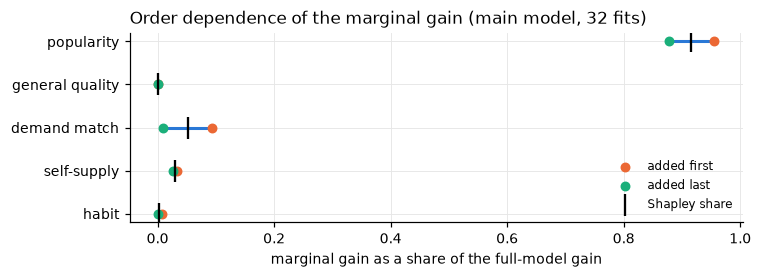

In [13]:
fig, ax = plt.subplots(figsize=(7, 2.6))
lab = {"pop": "popularity", "qual": "general quality", "match": "demand match", "self": "self-supply", "habit": "habit"}
for i, (g, r_) in enumerate(W.iterrows()):
    ax.plot([r_["min"] / tot, r_["max"] / tot], [i, i], color=C[0], lw=2, solid_capstyle="round")
    ax.scatter([r_["first"] / tot], [i], color=C[1], s=30, zorder=3, label="added first" if i == 0 else None)
    ax.scatter([r_["last"] / tot], [i], color=C[2], s=30, zorder=3, label="added last" if i == 0 else None)
    ax.scatter([r_["share"]], [i], color="black", marker="|", s=200, zorder=4, label="Shapley share" if i == 0 else None)
ax.set_yticks(range(len(W))); ax.set_yticklabels([lab.get(g, g) for g in W.index]); ax.invert_yaxis()
ax.set_xlabel("marginal gain as a share of the full-model gain")
ax.set_title("Order dependence of the marginal gain (main model, 32 fits)", loc="left")
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

In [14]:
sh = tab("v2s_P5_shapley")
sel = (sh.measure.isin(["in-sample", "holdout"])) & (sh.partition == "pop / fit / ...")
show(sh[sel][[c for c in ["measure", "variant", "group", "value", "share", "lo", "hi", "reps"] if c in sh]].round(4))

,measure,variant,group,value,share,lo,hi,reps
5,in-sample,no FE,popularity,723344.8029,0.9158,0.9115,0.9191,50.0
6,in-sample,no FE,fit (quality + match),41017.7555,0.0519,0.0497,0.0550,50.0
7,in-sample,no FE,self-supply,23051.2001,0.0292,0.0262,0.0337,50.0
8,in-sample,no FE,habit,2451.8081,0.0031,0.0026,0.0037,50.0
15,in-sample,FE as a player,popularity,416111.6992,0.5092,NaN,NaN,NaN
16,in-sample,FE as a player,fit (quality + match),32001.7958,0.0392,NaN,NaN,NaN
17,in-sample,FE as a player,self-supply,23294.7731,0.0285,NaN,NaN,NaN
18,in-sample,FE as a player,habit,2189.7217,0.0027,NaN,NaN,NaN
19,in-sample,FE as a player,FE,343621.0771,0.4205,NaN,NaN,NaN
25,holdout,no FE,popularity,6.0749,0.9170,NaN,NaN,NaN


**写作要点：**
- **正文：** $G(\mathcal S)$ 的定义和式 (4)，以及一句"Shapley 值是唯一满足有效性、对称性、零贡献和可加性的分配"。不需要写出公理的形式化表述。
- **工作示例（上图）很有说服力。** 例如，匹配组最先加入和最后加入时的贡献差别很大。建议在附录 C 放这张图，正文用一句话说明"顺序会改变结论，所以用 Shapley"。
- **份额的单位要讲清楚：** 这是"似然增益"的份额，不是"多少比例的选择是流行驱动的"。前者衡量的是"知道这组信号后，预测能力提高多少"。§13 有建议的表述。
- **草稿需要更新：** 草稿写的是"四组，$2^4=16$ 次拟合"。v2.1 主结果是五组（自供给与习惯拆开），需要 $2^5=32$ 次拟合；FE 作为第 6 个玩家时需要 64 次。

## 7. 通用质量的上界：枢纽固定效应

### 7.1 问题
benchmark 分数只覆盖少数模型（大部分候选的 `bench_na = 1`）。所以通用质量份额接近 0，可能是"开发者不在乎质量"，也可能只是"我们没测到质量"。

### 7.2 上界的构造
1. 在模型中加入 500 个枢纽的固定效应 $\phi_h$（§3.3）。$\phi_h$ 吸收枢纽**一切不随时间变化的属性**：不可观测的质量，也包括品牌、教程和默认地位。
2. 把 FE 作为 Shapley 的额外玩家，得到份额 $s_{FE}$。
3. **最宽的上界：** 把 $s_{FE}$ 全部算作质量，质量份额 $\le s_{qual}+s_{FE}$。这是任何不变的枢纽属性能贡献的最大份额。
4. **外部质量能解释多少：** 用枢纽的外部质量（Open LLM Leaderboard v2 平均分、Arena 评分，控制参数量和再分发账号）回归 $\hat\phi_h$。用解释的方差比例 $q$ 把 $s_{FE}$ 拆成质量部分 $q\,s_{FE}$ 和流行部分 $(1-q)\,s_{FE}$。

### 7.3 噪声校正的推导
$\hat\phi_h = \phi_h + e_h$，其中估计误差 $e_h$ 与真值不相关，方差为 $\sigma_h^2$（用 bootstrap 方差估计）。那么
$$\mathrm{Var}(\hat\phi) = \mathrm{Var}(\phi) + \overline{\sigma^2}\ \Rightarrow\ \widehat{\mathrm{Var}}(\phi) = \mathrm{Var}(\hat\phi) - \overline{\sigma^2}.$$
外部质量对真值的解释比例为
$$q = \frac{\mathrm{Var}(\hat b^\top z_h)}{\mathrm{Var}(\hat\phi) - \overline{\sigma^2}}.$$
（误差不进入拟合值的方差，所以分子不需要校正。）不校正时，分母偏大，$q$ 被低估，质量的上界偏松。只用 bootstrap 标准误小于 1 的枢纽。

### 7.4 一个需要在论文里坦白的近似
Shapley 份额对"把一个玩家拆成两部分"**不是线性的**。用 $q$ 按比例拆分 $s_{FE}$，等于假设 FE 中的质量部分与其余部分对似然增益的贡献与其方差成比例。严格的做法是把外部质量部分作为一个单独的玩家重新做 Shapley，但这需要所有枢纽都有外部质量，而覆盖率有限。建议在附录 D 说明这一点，并指出两个端点（$q=0$ 和 FE 全部算作质量）不依赖这个近似。

In [15]:
show(tab("v2_bounds").round(4))
qe = tab("v2_quality_ext")
show(qe[[c for c in ["source", "controls", "hubs", "share_of_fe", "r2_noise_corrected", "quality_part_share",
                     "var_phi", "mean_noise"] if c in qe]].round(4))

,bound,fit,popularity,fe_share,q,ratio_fit_pop
0,lower (no FE; quality = bench_z only),0.0520,0.9164,NaN,NaN,0.0568
1,FE all quality (in-sample; old-style upper bound),0.4598,0.5096,0.4206,NaN,0.9025
2,"external quality (v2 average, controls), in-sa...",0.0702,0.8992,0.4206,0.0735,0.0781
3,FE all quality (holdout; old-style upper bound),0.3622,0.6029,0.3230,NaN,0.6007
4,"external quality (v2 average, controls), holdout",0.0629,0.9022,0.3230,0.0735,0.0697


,source,controls,hubs,share_of_fe,r2_noise_corrected,quality_part_share,var_phi,mean_noise
0,v2 average,-,140,0.280,0.0212,0.0212,1.4007,0.0224
1,v2 average,redistributor,140,0.280,0.0361,0.0276,1.4007,0.0224
2,v2 average,redistributor+lparams,118,0.236,0.0427,0.0735,1.5065,0.0234
3,arena rating,-,49,0.098,0.2114,0.2114,1.3033,0.0425
4,arena rating,redistributor,49,0.098,0.3898,0.1309,1.3033,0.0425
5,arena rating,redistributor+lparams,41,0.082,0.3811,0.2157,1.4170,0.0458
6,native model-index,-,9,0.018,0.0777,0.0777,1.8671,0.0342
7,native model-index,redistributor,9,0.018,0.0777,0.0777,1.8671,0.0342
8,native model-index,redistributor+lparams,9,0.018,0.0866,0.2648,1.8671,0.0342
9,v2 average + arena (both covered),-,28,0.056,0.0646,0.0646,0.7388,0.0182


**写作要点：**
- **正文：** FE 模型的式子，以及"上界 = FE 份额全部算作质量"和"外部质量解释其中的 $q$"两句话。$q$ 的公式可以以一行的形式放进正文；噪声校正的推导放附录 D。
- **三档数字：**
  - 下界：无 FE，fit/pop = 0.057；
  - 外部质量校正后：0.078；
  - 最宽上界：0.90，即 FE 全部算作质量。

  这三档应该在 Section 5 用一张小表报告，方法节只定义。
- **留出集口径：** FE 在留出集上的份额更小，所以最宽上界在样本外更紧。这一点值得在正文提一句。
- **比例拆分的近似（§7.4）必须写。** 否则懂 Shapley 的审稿人会指出这一点。

## 8. 方法能否区分机制：恢复检验

### 8.0 这一节和前面的区别
| | §1–§7（估计） | §8（验证） |
|---|---|---|
| 已知 | 真实的选择 | 我们**自己设定**的"真实机制" |
| 未知 | 机制（系数、份额） | 方法能不能把这个机制找回来 |
| 流程 | 真实选择 → 估计 → 份额 | 设定的机制 → 生成假选择 → 用**同一套方法**估计 → 份额 → 与设定的机制对比 |

打个比方：前面是用秤称东西，这里是先用已知重量的砝码检查秤准不准。

**为什么需要：** 热门模型往往也匹配常见任务，各组特征相关。审稿人可以质疑"Shapley 分解会不会天生把功劳记到流行头上"。只有让真实机制已知，才能回答。

### 8.1 合成优先连接网络：检查整条代码管线
1. 用程序生成 8,000 个节点的网络，规则已知：新节点以权重 $d^{\alpha}$（$d>0$）或 $e^{\beta_0}$（$d=0$）连接已有节点，$\alpha=1$，$\beta_0=-1$。
2. 把它当成真实数据，跑**完全相同的代码**：重放时间顺序、计算 degree、抽候选集、算 $\log\pi$、估计条件 logit。
3. 检查 $\hat\alpha$ 是否接近 1。

管线中任何一处出错（degree 用了未来的边、$\pi$ 算错、修正漏了），$\hat\alpha$ 都会偏离 1。三种抽样设计下 $\hat\alpha$ 都在 1 的三个标准误之内；PPS 下每个节点的经验入选频率与 $\pi$ 一致。这些是 `tests/test_replay.py` 中的单元测试，不是研究结果。

### 8.2 在真实候选集上恢复已知机制
**不是**按特征组重新估计参数。分四步：

**第一步：设定"真实机制"，即效用。** 效用就是 §1 的 $V_{kl}=\theta^\top x_{kl}$。这里**不重新估计**，直接用主模型在真实数据上估出的系数 $\hat\theta$，只是保留不同的项：

| 情形 | 效用 $V_{kl}$ | 含义 |
|---|---|---|
| **SF** | $\sum_{f\in\text{流行组}}\hat\theta_f\,x_{kl,f}$ | 开发者**只看流行** |
| **QF** | $\hat\theta_{\text{qual}}\,\text{bench\_z}_{kl}+\sum_{f\in\text{匹配组}}\hat\theta_f\,x_{kl,f}+q_l$ | 开发者**只看质量和匹配**；$q_l$ 是枢纽 FE 中能被外部质量解释的部分（§7） |
| **FULL** | $\hat\theta^\top x_{kl}+\hat\phi_l$ | 完整的估计模型（含 FE） |

**第二步：生成假选择。** 对每一次真实的首次采纳 $k$：
- **不变：** 候选集 $\mathcal D_k$ 和每个候选的全部特征，都是真实数据；
- **换掉：** 真实的被选者 $j_k$。改为按设定的效用重新抽一个，抽中 $l$ 的概率是
$$P(l\mid\mathcal D_k) = \frac{\exp(V_{kl}-\log\pi_{kl})}{\sum_{m\in\mathcal D_k}\exp(V_{km}-\log\pi_{km})}.$$

这就是 SIR（sampling–importance–resampling）：按 HT 权重 $e^{V}/\pi$ 在样本上重抽，近似"在全市场上按 logit 抽取"。保留真实候选集和特征，是为了让各组特征的相关性与真实数据完全一样，检验的是方法**在真实的相关结构下**是否有效。

**第三步：** 把假选择当作真实数据，跑完整的分解（全部子集拟合 + Shapley），流程与主结果完全相同。

**第四步：** 与设定的机制对比。
- 如果分解能区分机制，SF 应当接近 100% 流行，QF 应当接近 100% 适合，FULL 应当恢复真实数据的份额。
- SF 和 QF 达不到 100%，是因为真实特征是相关的，一部分功劳"泄漏"给了相关的另一组。泄漏的大小（约 3–6%）本身就是分解误差的估计。
- **最重要的反证：** 当选择只由质量和匹配生成时（QF），分解**不会**制造出流行份额。所以真实数据中 92% 的流行份额不是方法的产物。

**与 Section 6 的关系：** SF 和 QF 也是增长网络的两个反事实。Section 6 用同样的效用生成整张网络、比较集中度；`v2_grow_recovery` 是带网络反馈的版本（SF 的 degree 随模拟更新）。


In [16]:
for name in ["v2_networks_recovery", "v2_grow_recovery"]:
    t = tab(name)
    t = t[t.partition == "pop / fit / inertia"].pivot(index="network", columns="group", values="share")
    print(name); show(t.round(4))

v2_networks_recovery


group,fit (quality + match),inertia,popularity
network,,,
FULL,0.0518,0.0318,0.9164
QF,0.9402,0.0032,0.0566
SF-SIR,0.0301,0.0005,0.9694


v2_grow_recovery


group,fit (quality + match),inertia,popularity
network,,,
EST,0.0478,0.0090,0.9432
QF,0.9248,0.0077,0.0676
SF,0.0148,0.0000,0.9852


**写作要点：**
- **正文：** 4.6 用文字描述两个检验和三个数字（96.9% 流行、94.0% 适合、FULL 恢复 91.6 / 5.2 / 3.2）。草稿已经这样写了。SIR 的式子放在附录 C。
- **把"不会制造流行份额"作为这一小节的核心句。** 这是对"Shapley 分解偏向高方差特征"这类质疑最直接的回答。
- **待更新：** 恢复检验目前用的是四组口径。v2.1 主结果改为五组后，FULL 的恢复值应写成流行 / 适合 / 自供给 / 习惯四项。可以重跑，也可以在附录说明"自供给 + 习惯 = 原惯性组"。

## 9. v2.1：样本、分组与加权的扩展

这一节对应本轮补做的样本选择检验，决定 Section 4 末尾和 Section 5 的稳健性部分怎么写。

### 9.1 五组特征：惯性拆成自供给与习惯
- **自供给：** `same_author`，即候选是作者自己发布的模型。这在机构账号中是组织行为（在自家基座上继续开发），不是心理上的惯性。
- **习惯：** `author_reuse`（用过的父模型）、`author_family`（用过的家族）、`is_last`（上一次用的父模型）。
- **在首次采纳中**，`author_reuse` 和 `is_last` 恒为 0，习惯组只剩 `author_family`。完整模型的特征与四组时完全相同，所以系数不变（P4 与 v2 主表逐位一致），只是 Shapley 的玩家数从 4 变为 5。

### 9.2 三级样本
- **U：** 全部上传，42.3 万次；
- **D：** 24h 决策，19.9 万次，包含重复决策；
- **P：** 首次采纳，13.3 万次，主结果。

在 D 和 U 中，作者用过的父模型以 $\pi=1$ 进入候选集（`author_reuse=1` 的行保留）。**Proposition 1 仍然成立**：这些候选的入选概率是 1，比值论证不变。

### 9.3 扣除自身的流行度
在重复决策中，候选 $j$ 的 degree 包含作者 $a$ 自己此前以 $j$ 为父的子模型。令
$$o_{kj} = \#\{c:\ \text{parent}(c)=j,\ \text{author}(c)=a(k),\ \text{birth}(c)<t_k\},$$
用 $\tilde d_{kj} = d_{kj}-o_{kj}$ 替换 $d_{kj}$，对应地替换 $\log d$、$\mathbb 1[d>0]$ 和 $\log(1+r_{30})$。在 P 中 $o_{kj}\equiv 0$，结果不变；这本身就是一项检验，已经通过。

### 9.4 作者等权
$$w_k = \frac{N/A}{n_{a(k)}},$$
其中 $N$ 是选择数，$A$ 是作者数，$n_a$ 是作者 $a$ 的选择数。每位作者的总权重相同，平均权重为 1，所以对数似然的量级可比。点估计变成"典型作者"的行为，而不是"典型选择"的行为。推断仍按作者聚类，bootstrap 的权重是 $w_k\xi_{a(k)}$。

### 9.5 按作者类型分开估计与异质性检验
六类作者（大机构、再分发账号、其他组织、高产 / 中等 / 轻度个人）分别估计。异质性的似然比检验：
$$LR = 2\Big(\sum_\tau\ell_\tau - \ell_{\text{pooled}}\Big)\ \sim\ \chi^2\Big(\sum_\tau k_\tau - k\Big).$$
注意：logit 的尺度在各类型之间可以不同，所以 LR 拒绝"系数相同"，可能部分来自尺度的差异。**份额**不受尺度影响，比系数更适合跨类型比较。

### 9.6 事先确定的判断规则
主结果是 P5（P、五组、按选择加权）。其他口径如果同时满足以下两条，就称"对样本选择稳健"：
- 流行份额与主结果的差距不超过 10 个百分点；
- 适合/流行比值在主结果的 1/3 到 3 倍之间。

In [17]:
rows = []
for f in sorted(glob.glob(f"{CH}/v2_samples/*/summary.pkl")):
    tag = f.split("/")[-2]
    S_ = pickle.load(open(f, "rb"))
    O = S_["shares"]
    O = O[(O.measure == "in-sample") & (O.variant == "no FE") & (O.partition == "pop / fit / ...")].set_index("group")
    cfg = S_["cfg"]
    r_ = dict(config=tag, sample=cfg["sample"], groups=cfg["groups"], weight=cfg["weight"],
              subset=cfg["atype"] or (f"drop top {cfg['drop_top']:.0%}" if cfg["drop_top"] else "all"),
              n_train=S_["info"]["n_train"], authors=S_["info"]["authors"])
    for g in ["popularity", "fit (quality + match)", "self-supply", "habit", "inertia", "ratio fit / popularity"]:
        if g in O.index:
            r_[g] = O.share[g]
    r_["boot_reps"] = int(O.reps.max()) if "reps" in O and O.reps.notna().any() else 0
    rows.append(r_)
RB = pd.DataFrame(rows).set_index("config")
if "ratio fit / popularity" not in RB or RB["ratio fit / popularity"].isna().any():
    RB["ratio fit / popularity"] = RB["fit (quality + match)"] / RB["popularity"]
m = RB.loc["P5"]
RB["d_pop_pts"] = 100 * (RB.popularity - m.popularity)
RB["ratio_vs_main"] = RB["ratio fit / popularity"] / m["ratio fit / popularity"]
RB["robust (rule)"] = (RB.d_pop_pts.abs() <= 10) & RB.ratio_vs_main.between(1 / 3, 3)
show(RB.round(4))
for name in ["v2s_hetero", "v2s_ladder"]:
    if os.path.exists(f"{TAB}/{name}.csv"):
        print(name); show(tab(name).round(4))

,sample,groups,weight,subset,n_train,authors,popularity,fit (quality + match),self-supply,habit,ratio fit / popularity,boot_reps,inertia,d_pop_pts,ratio_vs_main,robust (rule)
config,,,,,,,,,,,,,,,,
D5,decisions,five,choice,all,176061,61670,0.7306,0.0314,0.0188,0.2192,0.0429,50,NaN,-18.5134,0.7573,False
D5_indiv_heavy,decisions,five,choice,indiv_heavy,49095,762,0.6012,0.0767,0.0229,0.2992,0.1275,0,NaN,-31.4563,2.2487,False
D5_indiv_light,decisions,five,choice,indiv_light,70476,49780,0.8829,0.0100,0.0065,0.1005,0.0114,0,NaN,-3.2874,0.2006,False
D5_indiv_mid,decisions,five,choice,indiv_mid,42973,8439,0.6244,0.0308,0.0318,0.3130,0.0493,0,NaN,-29.1350,0.8694,False
D5_org_major,decisions,five,choice,org_major,304,34,0.5732,0.1390,0.1994,0.0884,0.2426,0,NaN,-34.2609,4.2776,False
D5_org_other,decisions,five,choice,org_other,9857,2476,0.6425,0.0606,0.0433,0.2536,0.0943,0,NaN,-27.3329,1.6630,False
D5_org_redistributor,decisions,five,choice,org_redistributor,3356,179,0.6410,0.0868,0.0015,0.2707,0.1354,0,NaN,-27.4741,2.3879,False
D5a,decisions,five,author,all,176061,61670,0.9035,0.0098,0.0094,0.0773,0.0108,50,NaN,-1.2261,0.1907,False
D5raw,decisions,five,choice,all,176061,61670,0.7383,0.0311,0.0157,0.2148,0.0421,50,NaN,-17.7469,0.7432,False


v2s_ladder


,sample,choices,authors,top1pct_share,choices_per_author,org_major,org_redistributor,org_other,indiv_heavy,indiv_mid,indiv_light,unclassified
0,U: all uploads,422714,69763,0.5667,6.0593,0.0013,0.0121,0.0600,0.5118,0.1952,0.2197,0.0
1,D: 24h decisions,199464,69763,0.3252,2.8592,0.0020,0.0183,0.0573,0.2721,0.2443,0.4060,0.0
2,P: first adoptions,133390,69763,0.2336,1.9120,0.0024,0.0169,0.0607,0.1792,0.2165,0.5242,0.0


**写作要点：**
- **Section 4 只需要定义**（五组、三级样本、作者等权、按类型估计、判断规则），结果放在 Section 5 的稳健性部分。建议在 4.4 末尾加一段"样本与权重"：说明主结果按选择加权、只用首次采纳，以及为什么。理由见笔记的讨论：首次采纳时作者依赖公开信号；重复选择的流行度被作者自己污染；状态依赖无法与持久偏好区分。
- **自供给 / 习惯的定义应在 Section 3 给出**（特征分组），Section 4 只说"五个玩家"。
- **判断规则要写明是事先确定的**，并如实报告哪些口径不满足。目前的结果是：所有偏离都朝"流行更主导"或"习惯挤占流行"的方向，没有任何口径让适合更重要。
- **跨类型比较用份额，不用系数**（尺度问题），这一点要在方法里说。
- 上表在作业全部完成后会包含 12 个类型配置和 U5；重跑本笔记即可更新。

## 10. 重复选择与留存的模型（Section 5/6 和附录 E 用）

### 10.0 这一节回答的是另一个问题
- **§1–§9 回答"开发者怎么挑父模型"：** 用首次采纳估计模型，再分解流行和适合。
- **§10 回答"挑得好不好"：** 作者第一次用了某个父模型之后，下一次还用不用它。继续用，说明这个父模型适合他（或者只是习惯）；用一次就换掉，可能说明不满意。所以"留下还是换"是"适合"的一个**事后证据**，比"孙模型数"更直接。

**时间顺序：** §10 在主模型估计完成之后做，用到主模型的系数（§1 的 $\hat\theta$），但和 §8 的验证无关。v2 先做了全部作者合在一起的版本，v2.1 又按作者类型分开做了一遍。

### 10.1 留下还是换
**要检验的假设：** 首次选择时匹配得越好的父模型，下一次越可能被继续使用。

**第一步：给每次首次选择的"匹配程度"打分。** 主模型里，一个候选的效用是各特征乘以系数之和。只取匹配组的那几项加起来，就是这个候选的"匹配得分"：
$$I_{\text{match},k} = \sum_{f\in\text{匹配组}}\hat\theta_f\,x_{kj_k,f}.$$
$j_k$ 是这次实际选中的父模型。同样可以算"流行得分" $I_{\text{pop},k}$、"自供给得分" $I_{\text{self},k}$ 等。这些得分就是**首次选择时，每一组特征让这个父模型显得多有吸引力**。

**第二步：看得分能否预测下一次是否留下。** 样本是此后还有下一次决策的首次采纳（75,016 次）。$R_k=1$ 表示下一次仍用同一个父模型。做一个普通的逻辑回归（$\Lambda$ 是 logistic 函数）：
$$\Pr(R_k=1) = \Lambda\big(\alpha + \beta_{\text{pop}}I_{\text{pop},k} + \beta_{\text{match}}I_{\text{match},k} + \dots + \gamma^\top z_k\big).$$
- $z_k$ 是控制变量：距下次决策的时间、下次任务是否相同、同家族是否出了新版本、作者经验。
- **关键是 $\beta_{\text{match}}$：** 大于 0，就说明匹配得越好越常留下。

### 10.2 作者固定效应：只在同一个作者内部比较
**问题：** 10.1 把所有作者混在一起，比较的是"不同作者的不同选择"。v2 的结果是 $\beta_{\text{match}}=-0.165$，即匹配越好越**不**留下，与直觉相反。

**原因是不同作者之间的构成差异**（我之前叫它"跨作者构成效应"）：
- 高产账号做过很多任务，候选与其"任务历史"重合的机会多，所以匹配得分普遍高；但它们是批量流水线，下一次几乎总是换（只有 2.8% 留下）。
- 轻度个人的匹配得分普遍低一些，但更常留下（36.6%）。
- 混在一起看，"匹配高"和"换掉"同时出现，于是系数为负。但这反映的是**谁在做选择**，而不是"匹配好导致换掉"。

**解决办法：** 只比较同一个作者自己的多次选择，即"同一个作者，匹配更好的那次是不是更常留下"。做法相当于给每个作者加一个自己的截距 $\alpha_a$（有的作者天生爱换，有的天生不换），让作者之间的差异不再进入比较。
- 作者有两万多个，直接估计两万多个截距会有偏（偶发参数问题）。条件 logit（Chamberlain 1980）用一个数学技巧把这些截距消掉，不用估计它们。
- 只有"既有留下也有换掉"的作者才提供信息。全部作者都留下或都换掉的，无从比较。

**结果：** 作者内部比较时，$\beta_{\text{match}}=+0.183$，方向变正，说明之前的负号是作者构成造成的。分类型看，轻度个人 +0.469，中等个人 +0.111，高产个人和组织不显著。

### 10.3 三分类：把"不留下"拆开
"下一次没用同一个父模型"包含两种完全不同的情况：
- **升级：** 换成同一家族的新版本（例如从 Llama-3 换到 Llama-3.1），这不代表不满意；
- **换掉：** 换成别的模型。

如果把两者都算作"不留下"，升级会被误读为不满意。所以用三个结果（留下 / 升级 / 换掉）的逻辑回归（多项 logit），分别看匹配得分对"升级"和"换掉"的影响。

### 10.4 福利是怎么定义的
**定义：** 如果作者当初选的是候选集中**匹配最好**的那个，而不是实际选的那个，下一次继续使用的概率会高多少。留存是"适合"的事后证据，所以用它衡量"没选到最匹配的"造成的损失。

**计算分三步：**
1. **匹配差距：** 在每次选择的候选中找到匹配得分最高的 $j^*$，差距 $\Delta_k = I_{\text{match}}(j^*) - I_{\text{match}}(\text{实际选的})\ge 0$。差距为 0 说明已经选到了最匹配的。
2. **换算成留存概率：** 10.2 的系数 $\beta_{\text{match}}$ 表示匹配得分每高 1，留下的对数几率高 $\beta$。换算成概率时乘以 $\bar p(1-\bar p)$，$\bar p$ 是平均留存率（逻辑回归的标准换算）：
$$\Delta\Pr(\text{留下}) \approx \beta_{\text{match}}\times\Delta_k\times\bar p(1-\bar p).$$
3. **平均：** 报告两个口径，"每次没选到最匹配的选择"的平均，以及"全部选择"的平均。

**个人作者的例子：** $\beta=0.221$，未选到最匹配时的平均差距 0.54，$\bar p=0.2825$：
$$0.221\times0.54\times0.2825\times0.7175\approx0.024,$$
即留存概率高 2.4 个百分点，相当于平均留存率的 8.6%。

**两点近似要在论文里写明：**
- 这是一阶近似，差距大时不精确；
- 作者固定效应模型不给出每个作者自己的留存率，所以用该类作者的平均留存率 $\bar p$ 来换算。

### 10.5 一个试过但不用的模型：两步选择
**想法：** 作者做重复决策时，可能分两步：
1. 先决定"用以前用过的"还是"试个新的"；
2. 再在选定的那一类里挑具体哪个。

（我之前把"以前用过的那些"叫"旧巢"，把"其余所有模型"叫"新巢"，这是嵌套 logit 的术语。）

**这个模型多了一个参数 $\lambda$，** 衡量同一类里的选项有多"可以互相替代"。例如作者常用的模型下架了，他是改用另一个用过的，还是去试新的。

**估计时遇到的困难：** 第一步需要知道"新的那一类"整体有多吸引人，也就是对几十万个模型的吸引力求和。我们只有约 300 个抽样候选，只能用加权的方式近似估计这个和：
$$\lambda\log\sum_{l\in\text{抽样的新模型}}\frac{1}{\pi_l}e^{V_l/\lambda}.$$

**结果不可信：**
- 估出 $\lambda\approx0.02$，意味着作者只在乎每一类里最好的那一个，这在行为上说不通。
- 为了检查，我们用已知 $\lambda=0.7$ 的模拟数据、50 万个模型的市场重跑这个方法，结果得到 0.10–0.47，标准误约 0.25，找不回真值；把抽样候选扩大 10 倍也没有用。

**原因：** 市场里有几十万个新模型，而作者用过的只有几个，所以第一步几乎总是"试新的"。第一步的结果几乎没有变化，数据里就没有关于 $\lambda$ 的信息。

**结论：** 不用这个模型，只用 10.1–10.3 这些更简单的模型。附录 E 保留这个论证：说明我们试过、为什么不可行，这对审稿人是有信息量的。


In [18]:
for name in ["v2s_retention_bytype_outcomes", "v2s_retention_welfare"]:
    if os.path.exists(f"{TAB}/{name}.csv"):
        print(name); show(tab(name).round(4))
if os.path.exists(f"{TAB}/v2s_retention_bytype.csv"):
    rb = tab("v2s_retention_bytype")
    fe_ = rb[(rb.model == "conditional logit, author FE") & rb["var"].isin(["I_pop", "I_match", "I_self", "I_habit"])]
    print("author-FE conditional logit, group indices"); show(fe_.pivot(index="stratum", columns="var", values="coef").round(3))
    show(fe_.pivot(index="stratum", columns="var", values="z").round(1))
nc = tab("v2_nested_check")
show(nc[["lam_new_true", "lam_old_true", "market", "seed", "mean_set", "lam_new", "se_new", "lam_old", "se_old"]].round(3))

v2s_retention_bytype_outcomes


,stratum,pairs,authors,stay,upgrade,switch,R180,fe_sample,fe_authors
0,all,75016,24553,0.1826,0.0578,0.7596,0.4066,20612,3998
1,individuals (light + mid),43339,22223,0.2825,0.0639,0.6536,0.3751,12697,3353
2,indiv_light,20099,14899,0.3658,0.0614,0.5728,0.4013,2552,1084
3,indiv_mid,23240,7324,0.2104,0.0661,0.7235,0.3525,10145,2269
4,indiv_heavy,23521,736,0.0275,0.0360,0.9364,0.5141,4910,304
5,organisations,8156,1594,0.0991,0.0884,0.8125,0.2643,3005,341


v2s_retention_welfare


,stratum,unit,beta_match_fe,se_beta,mean_fit_gap,pbar,d_pr_stay,se,rel_to_pbar,n_choices
0,all,per mismatched choice,0.1836,0.0225,0.4749,0.1826,0.0130,0.0016,0.0713,61352
1,all,per choice,0.1836,0.0225,0.2190,0.1826,0.0060,0.0007,0.0329,133047
2,individuals (light + mid),per mismatched choice,0.2209,0.0268,0.5397,0.2825,0.0242,0.0029,0.0855,36120
3,individuals (light + mid),per choice,0.2209,0.0268,0.1978,0.2825,0.0089,0.0011,0.0313,98566
4,indiv_light,per mismatched choice,0.4694,0.0639,0.4944,0.3658,0.0538,0.0073,0.1472,21857
5,indiv_light,per choice,0.4694,0.0639,0.1548,0.3658,0.0169,0.0023,0.0461,69793
6,indiv_mid,per mismatched choice,0.1107,0.0305,0.6091,0.2104,0.0112,0.0031,0.0532,14263
7,indiv_mid,per choice,0.1107,0.0305,0.3019,0.2104,0.0056,0.0015,0.0264,28773
8,indiv_heavy,per mismatched choice,-0.0727,0.0645,0.3685,0.0275,-0.0007,0.0006,-0.0260,18215
9,indiv_heavy,per choice,-0.0727,0.0645,0.2815,0.0275,-0.0005,0.0005,-0.0199,23845


author-FE conditional logit, group indices


var,I_habit,I_match,I_pop,I_self
stratum,,,,
all,-0.323,0.184,0.052,-0.073
indiv_heavy,1.114,-0.073,0.071,-0.085
indiv_light,-7.107,0.469,0.026,-0.091
indiv_mid,0.756,0.111,0.051,-0.077
individuals (light + mid),-0.009,0.221,0.043,-0.087
organisations,-4.220,0.043,0.111,0.053


var,I_habit,I_match,I_pop,I_self
stratum,,,,
all,-0.2,8.2,7.9,-4.8
indiv_heavy,0.3,-1.1,3.9,-2.4
indiv_light,-1.2,7.3,1.6,-1.6
indiv_mid,0.3,3.6,6.0,-3.8
individuals (light + mid),-0.0,8.2,5.8,-4.6
organisations,-1.0,0.7,5.2,1.5


,lam_new_true,lam_old_true,market,seed,mean_set,lam_new,se_new,lam_old,se_old
0,1.0,1.0,300,0,300.000,0.965,0.056,1.000,0.000
1,1.0,1.0,300,1,300.000,1.000,0.000,0.815,0.085
2,1.0,1.0,50000,0,302.483,0.901,2067.161,0.900,936.168
3,1.0,1.0,50000,1,302.319,1.000,0.000,0.001,0.000
4,0.7,0.5,300,0,300.000,0.646,0.046,0.436,0.040
5,0.7,0.5,300,1,300.000,0.795,0.054,0.508,0.054
6,0.7,0.5,50000,0,302.450,0.770,0.124,0.642,0.192
7,0.7,0.5,50000,1,302.289,0.696,0.147,0.218,0.146
8,0.3,0.3,300,0,300.000,0.308,0.019,0.308,0.025
9,0.3,0.3,300,1,300.000,0.311,0.018,0.275,0.025


**写作要点：**
- **这些模型都不进 Section 4 正文。** 留存的二元 logit 和作者 FE 的条件 logit 在 Section 5 或 6 用到时，用一个式子加一句"以作者的留存次数为条件，消去作者固定效应"即可。
- **福利的一阶近似（§10.4）**如果作为福利结果，需要在正文写出式子，并说明 $\bar p$ 是近似。
- **嵌套 logit 只放附录 E。** 草稿已经写了，建议保留"为什么不用"的论证，这是诚实且有信息量的。

## 11. 式子清单：正文 / 附录 / 不写

| # | 内容 | 建议位置 | 理由 |
|---|---|---|---|
| E1 | $U_{kl}=\theta^\top x_{kl}+\varepsilon_{kl}$ | 正文 4.1（行内） | 定义模型 |
| E2 | 条件 logit (1) | **正文 4.1** | 全文的核心 |
| E3 | Gumbel ⇒ logit 的积分推导 | 不写（引用） | 教科书内容 |
| E4 | $\pi_{kl}=\min\{1,c_k(d_{kl}+1)\}$ (2) | **正文 4.2** | 抽样设计是本文的方法贡献之一 |
| E5 | $c_k$ 的分段线性求解 | 附录 B | 实现细节 |
| E6 | 修正后的 logit (3)，Proposition 1 | **正文 4.2** | 正确性的核心 |
| E7 | $q(\mathcal D\mid j)$ 与比值 $\pi_l/\pi_j$ | 正文一句 + 附录 B 证明 | 让读者直观看到为什么成立 |
| E8 | 分层与均匀设计的 $\log q$ | 附录 B | 稳健性 |
| E9 | 加权对数似然 $\ell(\theta)$ | 正文 4.3（可选，行内） | 权重在 bootstrap 和作者等权中都会用到；写一次可以省掉后面的解释 |
| E10 | 梯度与 Hessian（凹性） | 附录 C；正文只写"凹的" | 为热启动提供理由 |
| E11 | FE 模型 $V=\theta^\top x+\sum_h\phi_h\mathbb 1[l=h]$ | **正文 4.5** | 质量上界的基础 |
| E12 | L2 惩罚 | 附录 D | 数值细节 |
| E13 | 聚类三明治方差 | 不写（引用 Cameron & Miller） | 标准方法 |
| E14 | 乘数 bootstrap 的权重 $w_k\xi_{a(k)}$ | 正文 4.3（行内） | 一句话即可 |
| E15 | 设计效应 $\sum_a n_a^2/N^2$ | 附录 C | 解释 SE 为何只缩小到 0.65 |
| E16 | 留出集增益的定义 | 正文 4.4（行内） | 份额的另一个口径 |
| E17 | $G(\mathcal S)$ 与 Shapley 值 (4) | **正文 4.4** | 结论的来源 |
| E18 | 粗粒度划分 $v'(\mathcal T)=G(\cup\mathcal T)$ | 正文一句 | "适合 = 质量 + 匹配"是怎么来的 |
| E19 | 质量份额的拆分 $q\,s_{FE}$ | 正文 4.5（一行） | 三档上界 |
| E20 | 噪声校正 $\mathrm{Var}(\hat\phi)-\overline{\sigma^2}$ | 附录 D | 推导 |
| E21 | SIR 抽取概率 | 附录 C | 恢复检验的细节 |
| E22 | 扣除自身的 degree $\tilde d$ | 附录 D 或 E | v2.1 稳健性 |
| E23 | 作者等权 $w_k=(N/A)/n_a$ | 正文 4.4 末尾（行内）或附录 D | 回应少数作者问题 |
| E24 | 异质性 LR 检验 | 附录 D | 稳健性 |
| E25 | 留存 logit、作者 FE 条件 logit | Section 5/6 正文（一个式子）+ 附录 E | 留存结果 |
| E26 | 留存福利 $\beta\Delta\bar p(1-\bar p)$ | 用作福利结果时写正文，否则附录 E | |
| E27 | 嵌套 logit 与 HT 包含值 | 附录 E | 说明为什么不用 |

**正文合计：** 编号公式 4–5 个（E2、E4、E6、E11、E17），其余是行内式。这和 EC 论文的常见篇幅一致。

## 12. 数字核对与草稿需要修改的地方
下面把 Section 4 草稿中写死的数字和宏与本笔记重算的值对照。

In [19]:
macros = dict(re.findall(r"\\newcommand\{\\(\w+)\}\{([^}]*)\}", open(f"{REPO}/ec_adoption/tables/numbers.tex").read()))
net = tab("v2_networks_recovery")
net = net[net.partition == "pop / fit / inertia"].set_index(["network", "group"]).share
chk_rows = [
    ("recSfPop", 100 * net[("SF-SIR", "popularity")]),
    ("recQfFit", 100 * net[("QF", "fit (quality + match)")]),
    ("recFullPop", 100 * net[("FULL", "popularity")]),
    ("recFullMatch", 100 * net[("FULL", "fit (quality + match)")]),
    ("recFullInertia", 100 * net[("FULL", "inertia")]),
    ("nFirst", int(ch.pair_first.sum())),
]
out = []
for k, v in chk_rows:
    out.append(dict(macro=k, in_paper=macros.get(k), recomputed=round(v, 1) if isinstance(v, float) else f"{v:,}"))
hard = [
    ("pi = 1 candidates per choice (text: 8.6)", f"{cs.certain.mean():.2f} all / {tr.certain.mean():.2f} train"),
    ("training rows (text: 35.2 million)", f"{info['rows_train'] / 1e6:.1f} million"),
    ("features (text: 26)", len(P5["feats"])),
    ("Shapley fits (text: 2^4 = 16)", f"2^{len(P5['groups'])} = {2 ** len(P5['groups'])} (v2.1)"),
    ("chosen parent with pi = 1", pct(cs.chosen_pi1.mean())),
]
for k, v in hard:
    out.append(dict(macro=k, in_paper="(hard-coded)", recomputed=v))
show(pd.DataFrame(out))

,macro,in_paper,recomputed
0,recSfPop,96.9,96.9
1,recQfFit,94.0,94.0
2,recFullPop,91.6,91.6
3,recFullMatch,5.2,5.2
4,recFullInertia,3.2,3.2
5,nFirst,"133,390","133,390"
6,pi = 1 candidates per choice (text: 8.6),(hard-coded),8.55 all / 8.39 train
7,training rows (text: 35.2 million),(hard-coded),35.2 million
8,features (text: 26),(hard-coded),26
9,Shapley fits (text: 2^4 = 16),(hard-coded),2^5 = 32 (v2.1)


**草稿 `4_method.tex` 需要修改的地方（请自己写作时处理）：**
1. **4.1 和 4.4：** "four groups" 改为五组（自供给、习惯）；"$2^4=16$ fits" 改为 32；FE 作为第 6 个玩家时为 64 次。
2. **4.2："8.6 candidates per choice have $\pi=1$"**，按上表统一口径。可以补一句"被选父模型中约 27% 的 $\pi=1$"。
3. **4.2 末尾：** 指向三种设计的对比（Section 5 或附录）。
4. **4.4 末尾新增"样本与权重"一段：** 主结果只用首次采纳、按选择加权，并说明理由；其他口径放在 Section 5。
5. **4.5：** 写出 FE 模型的式子，补一句比例拆分是近似（§7.4）。
6. **4.6：** 恢复检验的数字目前是四组口径，需要说明"自供给 + 习惯 = 原惯性组"，或者重跑恢复检验。
7. **Proposition 1 后：** 加一句"修正依赖 logit 的 IIA；在偏好异质时是近似，§5 按作者类型分开估计"。

## 13. EC 审稿人可能的追问与回答

| 追问 | 建议的回答（和证据所在） |
|---|---|
| 抽样修正依赖 IIA，偏好有异质性时还对吗？ | 在 logit 下精确；在混合 logit 下是近似（Guevara & Ben-Akiva 2013）。我们按作者类型分开估计（§9），各类型内部的份额都显示流行主导。三种抽样设计中 PPS 与分层结果一致，说明结论不由某种特定的候选集构成驱动。 |
| 开发者不可能考虑 34 万个模型，考虑集怎么办？ | 条件 logit 在全市场上的设定等价于"考虑集外的模型效用极低"。PPS 设计让每次选择都包含最可能被考虑的热门模型（约 27% 的被选父模型以 $\pi=1$ 入选）。考虑集本身受流行驱动，这正是我们测量的一部分：流行既影响"看到"也影响"选择"，本文不分开两者，在 Discussion 中说明。 |
| degree 与不可观测的质量相关，$\theta_{\log d}$ 是跟风吗？ | 我们不做因果解释（§1）。用枢纽 FE 给质量一个上界（§7）：即使把 FE 全部算作质量，流行仍占约一半；外部质量只能解释 FE 的约 7%。同权重副本的比较（附录）进一步把质量固定住。 |
| "似然增益的份额"是什么意思？ | 它衡量"知道这组信号后，预测真实父模型的能力提高多少"，单位是对数似然，可以直观地翻译为"真实父模型的概率提高多少倍"。它不是"多少比例的开发者是跟风者"，后者需要潜类别模型（附录，结论方向一致）。 |
| Shapley 分解会偏向方差大的特征吗？ | 恢复检验（§8）：选择只由质量和匹配生成时，分解给出 94% 的适合份额，并没有制造流行份额。 |
| 为什么只用首次采纳？少数作者上传了大部分模型。 | 首次采纳对应"作者如何挑选"；重复选择混入了状态依赖，以及作者自身对流行度的污染。三级样本、作者等权、去掉头部作者的结果都在 Section 5，所有偏离都朝"流行更主导"的方向（§9）。 |
| 为什么不用 BLP 一类的需求模型？ | 没有价格，也不是总量市场份额数据。我们观察到的是个体选择和完整的候选特征，个体层面的条件 logit 是更自然的设定。Overgoor et al. (2019) 的网络增长框架也是这种形式。 |
| 标准误为什么不随样本量按 $\sqrt{n}$ 缩小？ | 按作者聚类，有效样本量是作者数（附录 C 的设计效应）。 |